# Лабораторная работа 1. Дискретное пространство состояний

**Вариант:** [RedBlueDoorEnv](https://minigrid.farama.org/environments/minigrid/RedBlueDoorEnv/) из библиотеки MiniGrid.

**Миссия агента:** «open the red door then the blue door» — сначала открыть красную дверь, потом синюю.

## Пункт 1. Библиотека окружений Gymnasium

### 1.0. Выбор конфигурации

У варианта две зарегистрированные конфигурации: `MiniGrid-RedBlueDoors-6x6-v0` и `MiniGrid-RedBlueDoors-8x8-v0`. В задании размер не указан, поэтому **выбираем 6x6**.

**Обоснование.** В пунктах 3–6 используются *табличные* методы (value iteration, Q-learning, SARSA): ценность хранится отдельно для каждого состояния, и каждое состояние нужно посетить много раз. Ниже (п. 1.4) мы посчитаем, что у 6x6 около 3 тыс. состояний. У 8x8 комната 6×6 вместо 4×4 и 36 расстановок дверей вместо 16, то есть состояний в 5–6 раз больше. Устройство задачи от этого не меняется, растёт только время обучения.

Сид фиксируем (`SEED = 0`), чтобы карта и все картинки воспроизводились при перезапуске ноутбука.

In [1]:
import copy
from collections import Counter, deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from gymnasium import Wrapper
from minigrid.core.actions import Actions
from minigrid.core.constants import IDX_TO_COLOR, IDX_TO_OBJECT, OBJECT_TO_IDX
from minigrid.wrappers import FullyObsWrapper  # импорт minigrid регистрирует среды MiniGrid-* в gymnasium

ENV_ID = "MiniGrid-RedBlueDoors-6x6-v0"
SEED = 0

### 1.1. Среда без обёрток

Создаём среду так, как она зарегистрирована, и смотрим на её пространства. `render_mode="rgb_array"`: `render()` возвращает картинку в виде массива, который рисуем через matplotlib (окно pygame в ноутбуке не нужно).

observation_space: Dict('direction': Discrete(4), 'image': Box(0, 255, (7, 7, 3), uint8), 'mission': MissionSpace(<function RedBlueDoorEnv._gen_mission at 0x00000182769AA7A0>, None))
action_space:      Discrete(7)
сетка (width x height): 12 x 6
max_steps: 720
mission:   open the red door then the blue door
obs['image'].shape: (7, 7, 3)   obs['direction']: 1


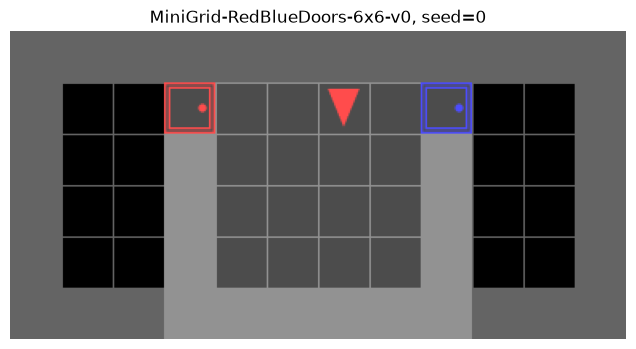

In [2]:
raw_env = gym.make(ENV_ID, render_mode="rgb_array")
obs, info = raw_env.reset(seed=SEED)
u = raw_env.unwrapped  # сама RedBlueDoorEnv под служебными обёртками gymnasium

print("observation_space:", raw_env.observation_space)
print("action_space:     ", raw_env.action_space)
print("сетка (width x height):", u.width, "x", u.height)
print("max_steps:", u.max_steps)
print("mission:  ", obs["mission"])
print("obs['image'].shape:", obs["image"].shape, "  obs['direction']:", obs["direction"])

plt.figure(figsize=(8, 4))
plt.imshow(raw_env.render())
plt.axis("off")
plt.title(f"{ENV_ID}, seed={SEED}")
plt.show()

**Что видим.**

- **Карта** 12×6 (ширина `2·size`). В центре комната 4×4, красная дверь в левой стене, синяя в правой. За дверями пустые «коридоры» 2×4. Позиции дверей по вертикали и стартовое положение агента выбираются случайно при каждом `reset`.
- **Наблюдение** — словарь из трёх полей:
  - `image` — закодированная картинка 7×7 **только перед агентом** (на рендере это светлая подсвеченная область; чёрные клетки — пол вне поля зрения);
  - `direction` — направление взгляда (0 →, 1 ↓, 2 ←, 3 ↑);
  - `mission` — текст задания. Он всегда один и тот же, поэтому в состояние его не включаем.
- **Частичная наблюдаемость.** По окну 7×7 агент не всегда видит обе двери и не знает, где именно стоит. Разные состояния мира могут давать одно и то же наблюдение, а табличным методам нужно, чтобы наблюдение однозначно задавало состояние. Поэтому дальше применяем `FullyObsWrapper` (п. 1.3).
- **Лимит шагов:** `max_steps = 20·size² = 720`. По его достижении эпизод обрывается (`truncated=True`).

### 1.2. Пространство действий

`Discrete(7)`. Смысл действий задан перечислением `minigrid.core.actions.Actions`:

In [3]:
for a in Actions:
    print(a.value, a.name)

0 left
1 right
2 forward
3 pickup
4 drop
5 toggle
6 done


В документации RedBlueDoorEnv действия `pickup`, `drop` и `done` помечены как *Unused*: на карте нет предметов, а `done` в `MiniGridEnv.step` ничего не делает. Проверим это: после каждого из них наблюдение не меняется, но счётчик шагов растёт.

In [4]:
obs0, _ = raw_env.reset(seed=SEED)
for a in [Actions.pickup, Actions.drop, Actions.done]:
    obs1, r, term, trunc, _ = raw_env.step(a)
    same = np.array_equal(obs0["image"], obs1["image"]) and obs0["direction"] == obs1["direction"]
    print(f"{a.name:7s}: наблюдение не изменилось = {same}, r = {r}, step_count = {raw_env.unwrapped.step_count}")

# Действия, которые реально меняют состояние среды
USEFUL_ACTIONS = [int(Actions.left), int(Actions.right), int(Actions.forward), int(Actions.toggle)]
ACTION_NAMES = {a.value: a.name for a in Actions}
print("Полезные действия:", [ACTION_NAMES[a] for a in USEFUL_ACTIONS])

pickup : наблюдение не изменилось = True, r = 0, step_count = 1
drop   : наблюдение не изменилось = True, r = 0, step_count = 2
done   : наблюдение не изменилось = True, r = 0, step_count = 3
Полезные действия: ['left', 'right', 'forward', 'toggle']


**Вывод.** Значимых действий четыре: `left` и `right` (поворот на 90°), `forward` (шаг вперёд, если клетка свободна или там открытая дверь) и `toggle` (открыть или закрыть дверь перед собой). Остальные три — это «стоять на месте», они только тратят шаг. В пунктах 3–6 будем перебирать только `USEFUL_ACTIONS`: таблица Q становится почти вдвое меньше (4 действия вместо 7), а оптимальная стратегия не меняется, потому что бесполезное действие никогда не может быть лучше полезного.

### 1.3. Обёртка `FullyObsWrapper`

Обёртка заменяет `image` на закодированную **всю** сетку. Каждая клетка — тройка `(OBJECT, COLOR, STATE)`:

- `OBJECT`: 1 — пусто, 2 — стена, 4 — дверь, 10 — агент;
- `COLOR`: 0 — red, 2 — blue, 5 — grey (у стен);
- `STATE`: для двери 0 — открыта, 1 — закрыта, 2 — заперта; в клетке агента — его направление.

Массив индексируется как `image[x][y]`, поэтому при печати транспонируем (`.T`), чтобы строки соответствовали `y`, как на картинке.

In [5]:
env = FullyObsWrapper(gym.make(ENV_ID, render_mode="rgb_array"))
obs, _ = env.reset(seed=SEED)
print("observation_space['image']:", env.observation_space["image"])
print("obs['image'].shape:", obs["image"].shape)


def show_layers(obs):
    # Три слоя кодировки; .T — чтобы строки были y, столбцы x (как на рендере)
    for k, name in enumerate(["OBJECT", "COLOR", "STATE"]):
        print(f"--- {name} ---")
        print(obs["image"][:, :, k].T)


def ascii_map(obs):
    # Наглядная карта: # стена, . пусто, R/B закрытая красная/синяя дверь, r/b открытая, стрелка — агент
    img = obs["image"]
    width, height, _ = img.shape
    rows = []
    for y in range(height):
        row = ""
        for x in range(width):
            obj, color, state = img[x, y]
            name = IDX_TO_OBJECT[obj]
            if name == "agent":
                row += ">v<^"[state]
            elif name == "door":
                letter = "R" if IDX_TO_COLOR[color] == "red" else "B"
                row += letter if state == 1 else letter.lower()
            else:
                row += {"wall": "#", "empty": "."}[name]
        rows.append(row)
    print("\n".join(rows))


show_layers(obs)
print("--- карта ---")
ascii_map(obs)

observation_space['image']: Box(0, 255, (12, 6, 3), uint8)
obs['image'].shape: (12, 6, 3)
--- OBJECT ---
[[ 2  2  2  2  2  2  2  2  2  2  2  2]
 [ 2  1  1  4  1  1 10  1  4  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  2  2  2  2  2  2  2  2  2  2  2]]
--- COLOR ---
[[5 5 5 5 5 5 5 5 5 5 5 5]
 [5 0 0 0 0 0 0 0 2 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 5 5 5 5 5 5 5 5 5 5 5]]
--- STATE ---
[[0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 1 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]]
--- карта ---
############
#..R..v.B..#
#..#....#..#
#..#....#..#
#..#....#..#
############


**Что видим.** В слое `OBJECT` стены (2), пустые клетки (1), две двери (4) и агент (10). У пустых клеток `COLOR = 0`: это не «красный», а заглушка, потому что пустая клетка кодируется как `(1, 0, 0)`. В слое `STATE` у обеих дверей стоит 1 (закрыты), а в клетке агента его направление. Клетку под агентом обёртка затирает тройкой `(10, red, dir)`. Это не теряет информацию: агент может стоять только на пустой клетке или в проёме *открытой* двери.

**Почему такое наблюдение годится как состояние MDP.** В пункте 3 задание предлагает ключ `image + direction + carrying`. Проверим, что он содержит всё, от чего зависит будущее:

- положение агента и обеих дверей видно в `image`;
- открыта ли каждая дверь — тоже в `image` (слой `STATE`), так что отдельно добавлять «информацию о дверях» не нужно;
- направление есть и в `image`, и в `direction`;
- `carrying` в этой среде всегда `None` (предметов нет), его оставляем ради совместимости с формулой из задания.

Не хватает только счётчика шагов `step_count`, а от него зависит награда. К этому вернёмся в п. 1.6.

In [6]:
def state_key(obs, env):
    # Ключ состояния из задания (пункт 3): вся сетка + направление + что несёт агент
    return str(obs["image"].flatten().tolist() + [obs["direction"], env.unwrapped.carrying])

### 1.4. Размер пространства состояний

`observation_space` формально огромный: `Box(0, 255, (12, 6, 3))`. Но реально достижимых состояний мало, и их можно перебрать.

**Расстановки и старты.** Переберём много сидов и посчитаем разные расстановки дверей и стартовые положения агента.

In [7]:
layouts, starts = set(), set()
for seed in range(2000):
    o, _ = env.reset(seed=seed)
    doors = np.argwhere(o["image"][:, :, 0] == OBJECT_TO_IDX["door"])
    layouts.add(tuple(map(tuple, doors.tolist())))
    starts.add((tuple(map(int, env.unwrapped.agent_pos)), int(env.unwrapped.agent_dir)))
print("Различных расстановок дверей:", len(layouts), "(красная: 4 варианта по y, синяя: 4 варианта по y)")
print("Различных стартов агента:    ", len(starts), "(16 клеток комнаты x 4 направления)")

Различных расстановок дверей: 16 (красная: 4 варианта по y, синяя: 4 варианта по y)
Различных стартов агента:     64 (16 клеток комнаты x 4 направления)


**Достижимые состояния при одной расстановке.** У MiniGrid нет явной модели переходов $P(s'|s,a)$, как у `mdp.py` из семинара. Зато среду можно скопировать (`copy.deepcopy(env)`), сделать в копии шаг и посмотреть, куда она попала. На этом приёме будет держаться и value iteration в пункте 3. Здесь используем его для обхода в ширину (BFS) всех состояний, достижимых из старта.

In [8]:
def reachable_states(env, obs, actions=USEFUL_ACTIONS):
    # BFS по состояниям: ключ -> копия окружения в этом состоянии
    start = state_key(obs, env)
    states = {start: copy.deepcopy(env)}
    queue = deque([start])
    n_terminal_transitions = 0
    while queue:
        e = states[queue.popleft()]
        for a in actions:
            e2 = copy.deepcopy(e)  # шаг делаем в копии, чтобы не испортить исходное состояние
            o, r, term, trunc, _ = e2.step(a)
            if term:
                n_terminal_transitions += 1
                continue
            k = state_key(o, e2)
            if k not in states:
                states[k] = e2
                queue.append(k)
    return states, n_terminal_transitions


obs, _ = env.reset(seed=SEED)
states, n_term = reachable_states(env, obs)
print("Достижимых нетерминальных состояний:", len(states))
print("Переходов в терминальные состояния: ", n_term)


def category(e):
    u = e.unwrapped
    x = u.agent_pos[0]
    red = "красная открыта" if u.red_door.is_open else "красная закрыта"
    where = "левый коридор" if x < u.size // 2 else ("проём красной двери" if x == u.size // 2 else "комната")
    return red, where


for (red, where), n in sorted(Counter(category(e) for e in states.values()).items()):
    print(f"  {red:16s} | агент: {where:20s} | {n:3d} = {n // 4:2d} кл. x 4 направления")
print("Всего нетерминальных состояний по всем расстановкам: 16 x", len(states), "=", 16 * len(states))

Достижимых нетерминальных состояний: 196
Переходов в терминальные состояния:  2
  красная закрыта  | агент: комната              |  64 = 16 кл. x 4 направления
  красная закрыта  | агент: левый коридор        |  32 =  8 кл. x 4 направления
  красная открыта  | агент: комната              |  64 = 16 кл. x 4 направления
  красная открыта  | агент: левый коридор        |  32 =  8 кл. x 4 направления
  красная открыта  | агент: проём красной двери  |   4 =  1 кл. x 4 направления
Всего нетерминальных состояний по всем расстановкам: 16 x 196 = 3136


**Разбор числа 196.**

| Красная дверь | Где агент | Клеток | Состояний |
|---|---|---|---|
| закрыта | комната | 16 | 64 |
| открыта | комната | 16 | 64 |
| открыта | проём двери | 1 | 4 |
| открыта | левый коридор | 8 | 32 |
| закрыта | левый коридор (вышел и закрыл за собой) | 8 | 32 |

Синяя дверь во всех нетерминальных состояниях закрыта: стоит её открыть, и эпизод заканчивается. В правый коридор агент поэтому попасть не может.

Переходов в терминальные состояния всего 2. Оба — это `toggle` из клетки перед синей дверью лицом к ней: при открытой красной это успех, при закрытой — провал. Из 196·4 = 784 пар (состояние, действие) награду может дать только одна, поэтому награда такая разреженная. Для разных расстановок множества состояний не пересекаются (двери в `image` стоят в разных местах), так что всего $16 \cdot 196 = 3136$ состояний. Это легко помещается в словарь, поэтому в пункте 3 можно перебирать все состояния, а не использовать вариант для «очень многих состояний».

### 1.5. Несколько шагов с картинками: как меняется награда

Награда в `RedBlueDoorEnv.step` (см. исходник `minigrid/envs/redbluedoors.py`):

- открыта **синяя** дверь, когда **красная уже открыта** → успех, $r = 1 - 0.9 \cdot \frac{step\_count}{max\_steps}$, эпизод завершается (`terminated=True`);
- открыта синяя дверь, когда красная закрыта → провал, $r = 0$, эпизод тоже завершается;
- на всех остальных шагах $r = 0$.

Помощник ниже проигрывает заданную последовательность действий, печатает таблицу наград и рисует кадр после каждого шага.

In [9]:
def run_actions(env, actions, seed=SEED, title="", draw=True, ncols=4):
    obs, _ = env.reset(seed=seed)
    frames = [(env.render(), "старт")]
    total = 0
    print(f"{'шаг':>3} | {'действие':8s} | {'r':>6s} | term  | trunc")
    for t, a in enumerate(actions, 1):
        obs, r, term, trunc, _ = env.step(a)
        total += r
        print(f"{t:3d} | {ACTION_NAMES[a]:8s} | {r:6.4f} | {term!s:5s} | {trunc}")
        frames.append((env.render(), f"{t}: {ACTION_NAMES[a]}, r={r:.4f}"))
        if term or trunc:
            break
    print("Суммарная награда:", round(total, 4))
    if draw:
        nrows = -(-len(frames) // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows))
        for ax in axes.flat:
            ax.axis("off")
        for ax, (img, caption) in zip(axes.flat, frames):
            ax.imshow(img)
            ax.set_title(caption, fontsize=10)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return total


L, R, F, T = int(Actions.left), int(Actions.right), int(Actions.forward), int(Actions.toggle)

**(а) Успешный сценарий.** На карте сида 0 (см. п. 1.3) агент стоит в клетке (6, 1) и смотрит вниз, красная дверь в (3, 1), синяя в (8, 1), все в верхнем ряду комнаты. План: повернуться налево (`right` из «вниз» даёт «влево»), дойти до красной двери, открыть её, развернуться, дойти до синей и открыть её. Получается 10 действий, и короче нельзя. Нужно 1 поворот к красной двери, 2 шага до неё, 1 `toggle`, 2 поворота для разворота, 3 шага до синей двери и ещё 1 `toggle`: $1+2+1+2+3+1 = 10$.

шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | forward  | 0.0000 | False | False
  9 | forward  | 0.0000 | False | False
 10 | toggle   | 0.9875 | True  | False
Суммарная награда: 0.9875


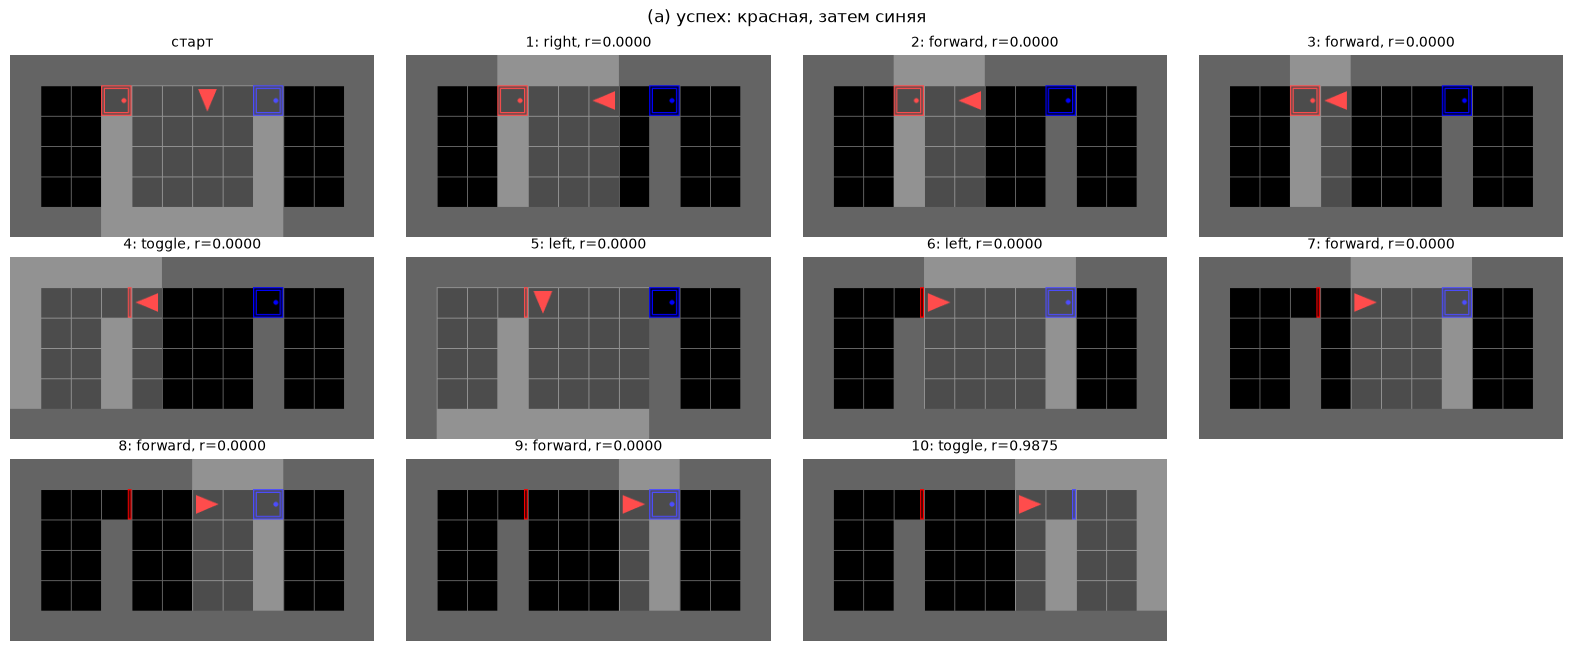

По формуле: 1 - 0.9 * 10 / 720 = 0.9875


In [10]:
success = [R, F, F, T, L, L, F, F, F, T]
r_a = run_actions(env, success, title="(а) успех: красная, затем синяя")
print("По формуле: 1 - 0.9 * 10 / 720 =", round(1 - 0.9 * 10 / env.unwrapped.max_steps, 4))

Награда нулевая на всех шагах, кроме последнего. Открытие красной двери (шаг 4) **не награждается**, хотя это необходимый подшаг. Награда разреженная: агенту придётся самому выяснить, что открытие красной двери полезно. В пунктах 2–3 это видно по тому, как ценность «растекается» назад от финала.

**(б) Провал: синяя дверь первой.** Из того же старта повернуться направо, сделать шаг и открыть синюю дверь.

шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | toggle   | 0.0000 | True  | False
Суммарная награда: 0


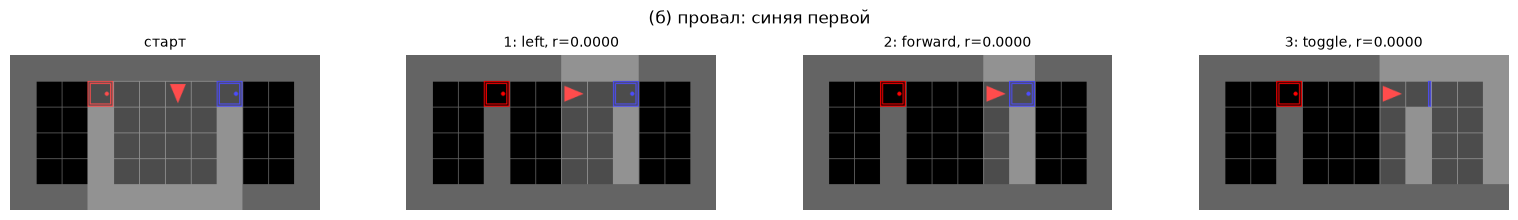

In [11]:
fail = [L, F, T]
r_b = run_actions(env, fail, title="(б) провал: синяя первой")

Эпизод завершился (`terminated=True`) с наградой 0. Провал и обычный шаг дают одинаковую награду, но провал *обрывает* эпизод, и награду 1 в нём уже не получить. Поэтому ценность такого действия будет нулевой.

Замечание: красную дверь можно открывать и закрывать сколько угодно. Если закрыть её и потом открыть синюю, это тоже провал: среда проверяет, открыта ли красная дверь *в момент* открытия синей.

**(в) Тот же успех с лишними действиями.** Перед успешным сценарием добавим полный оборот на месте (4 × `left`): агент возвращается в то же самое состояние, но тратит 4 шага.

In [12]:
detour = [L, L, L, L] + success
r_c = run_actions(env, detour, title="(в) успех с полным оборотом в начале", draw=False)
print("По формуле: 1 - 0.9 * 14 / 720 =", round(1 - 0.9 * 14 / env.unwrapped.max_steps, 4))

шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | left     | 0.0000 | False | False
  3 | left     | 0.0000 | False | False
  4 | left     | 0.0000 | False | False
  5 | right    | 0.0000 | False | False
  6 | forward  | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | toggle   | 0.0000 | False | False
  9 | left     | 0.0000 | False | False
 10 | left     | 0.0000 | False | False
 11 | forward  | 0.0000 | False | False
 12 | forward  | 0.0000 | False | False
 13 | forward  | 0.0000 | False | False
 14 | toggle   | 0.9825 | True  | False
Суммарная награда: 0.9825
По формуле: 1 - 0.9 * 14 / 720 = 0.9825


### 1.6. Почему исходная награда не марковская

Сравним **последний переход** в сценариях (а) и (в): состояние до шага, действие и состояние после.

In [13]:
def last_transition(env, actions, seed=SEED):
    obs, _ = env.reset(seed=seed)
    for a in actions[:-1]:
        obs, *_ = env.step(a)
    s = state_key(obs, env)
    obs2, r, *_ = env.step(actions[-1])
    return s, actions[-1], state_key(obs2, env), r


s1, a1, s1_next, r1 = last_transition(env, success)
s2, a2, s2_next, r2 = last_transition(env, detour)
print("s одинаковые: ", s1 == s2)
print("a одинаковые: ", a1 == a2)
print("s' одинаковые:", s1_next == s2_next)
print("r:", round(r1, 4), "vs", round(r2, 4))

s одинаковые:  True
a одинаковые:  True
s' одинаковые: True
r: 0.9875 vs 0.9825


Один и тот же переход $(s, a, s')$ дал разные награды. Награда зависит от `step_count`, а его нет в наблюдении. Значит, функции $r(s, a, s')$, которая нужна в уравнении Беллмана $V(s) = \max_a [r(s,a,s') + \gamma V(s')]$, просто не существует: процесс с таким состоянием **не марковский**.

Это можно исправить двумя способами:

1. Добавить номер шага в состояние. Тогда пространство состояний вырастет примерно в 720 раз.
2. Убрать зависимость награды от времени. Именно это предлагает задание.

### 1.7. Обёртка `BinaryRewardWrapper`

Класс взят из задания без изменений: любая ненулевая награда превращается в 1.

In [14]:
class BinaryRewardWrapper(Wrapper):
    def step(self, action):
        observation, reward, terminated, truncated, info = self.env.step(action)
        bin_reward = 1 if reward != 0 else 0
        return observation, bin_reward, terminated, truncated, info


def make_env():
    # Окружение, с которым работаем во всех следующих пунктах
    return BinaryRewardWrapper(FullyObsWrapper(gym.make(ENV_ID, render_mode="rgb_array")))


env = make_env()
print("(а) успех:")
run_actions(env, success, draw=False)
print("\n(в) успех с оборотом:")
run_actions(env, detour, draw=False)
print("\n(б) провал:")
run_actions(env, fail, draw=False)
s1, a1, s1_next, r1 = last_transition(env, success)
s2, a2, s2_next, r2 = last_transition(env, detour)
print("\nТот же последний переход теперь даёт одинаковую награду:", r1, "==", r2)

(а) успех:
шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | forward  | 0.0000 | False | False
  9 | forward  | 0.0000 | False | False
 10 | toggle   | 1.0000 | True  | False
Суммарная награда: 1

(в) успех с оборотом:
шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | left     | 0.0000 | False | False
  3 | left     | 0.0000 | False | False
  4 | left     | 0.0000 | False | False
  5 | right    | 0.0000 | False | False
  6 | forward  | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | toggle   | 0.0000 | False | False
  9 | left     | 0.0000 | False | False
 10 | left     | 0.0000 | False | False
 11 | forward  | 0.0000 | False | False
 12 | forward  | 0.0000 |

**Почему обёртка корректна.**

- **Бинаризация ничего не смешивает.** В этой среде ненулевую награду даёт только успех: провал и обычные шаги и так дают 0. Новая награда равна 1 ровно в случае успеха и зависит только от перехода $(s, a, s')$, так что процесс становится марковским.
- **Стремление к короткому пути не теряется.** Раньше скорость поощрялась множителем $1 - 0.9 \cdot step/720$. Теперь её обеспечит дисконт $\gamma < 1$ в пунктах 2–6: успех через $k$ шагов стоит $\gamma^{k-1}$, и чем путь короче, тем ценность больше.
- **Порядок обёрток не важен.** `FullyObsWrapper` меняет только наблюдение, `BinaryRewardWrapper` только награду. Мы ставим `FullyObsWrapper` внутрь, потому что он наследуется от `ObservationWrapper` и работает с наблюдением сразу после среды.
- **Обрыв по лимиту.** Если за 720 шагов не дойти до цели, эпизод обрывается с наградой 0 и `truncated=True`. Это не терминальное состояние MDP (`terminated=False`), а внешнее прерывание, и при обучении его нужно отличать от `terminated`.

### Итоги пункта 1

1. **Среда:** `MiniGrid-RedBlueDoors-6x6-v0`, сетка 12×6, комната 4×4. 16 расстановок дверей, 64 стартовых положения.
2. **Действия:** `Discrete(7)`, но полезны только 4 (`left`, `right`, `forward`, `toggle`). `pickup`, `drop` и `done` ничего не делают.
3. **Наблюдение:** без обёрток видно только окно 7×7 перед агентом, то есть среда частично наблюдаема. С `FullyObsWrapper` видна вся сетка (12, 6, 3), включая состояния дверей. Ключ `image + direction + carrying` однозначно задаёт состояние мира, кроме счётчика шагов.
4. **Пространство состояний:** 196 нетерминальных состояний на расстановку, всего 3136. Это легко перебрать, поэтому в пункте 3 подходит полный перебор.
5. **Награда:** разреженная, есть только за успех и уменьшается с числом шагов. Из-за этого она не марковская: один и тот же переход даёт разную награду. `BinaryRewardWrapper` превращает её в индикатор успеха, а предпочтение коротких путей переходит к дисконту $\gamma$.
6. **Инструмент для дальнейших пунктов:** `make_env()`, `state_key()`, `USEFUL_ACTIONS` и приём «шаг в `deepcopy(env)`» вместо модели переходов.

## Пункт 2. Оценка ценности состояний вручную

### 2.0. Постановка

Метод последовательных приближений для уравнения Беллмана:

$$V_{i+1}(s) = \max_a \big[\, r(s,a,s') + \gamma V_i(s') \,\big]$$

**Почему формула именно такая.** В общем случае внутри стоит мат. ожидание по следующему состоянию: $\sum_{s'} P(s'|s,a)\,[r + \gamma V_i(s')]$. Наша среда **детерминированная**: из состояния $s$ действие $a$ всегда ведёт в одно и то же $s'$. Поэтому сумма вырождается в одно слагаемое и остаётся просто $\max_a$.

**Параметры.**

- $\gamma = 0.9$, как в семинаре `seminar_vi.ipynb`. Любое $0<\gamma<1$ подходит; при 0.9 степени $\gamma^k$ хорошо различимы на глаз: 1, 0.9, 0.81.
- $V_0(s) = 0$ для всех $s$. Это означает: «пока ничего не знаем о ценностях». Сходимость от начального приближения не зависит, а с нулём легко считать руками.
- **Терминальные состояния** (эпизод окончен, успехом или провалом) имеют $V = 0$, потому что после них наград больше не будет. Поэтому для перехода в терминальное $s'$ остаётся только $r$.
- Награда **бинарная** (после `BinaryRewardWrapper` из п. 1.7): $r = 1$ только за открытие синей двери при открытой красной, иначе 0.

**Карта.** Считаем для сида 0 из п. 1.3:

```
x:  0 1 2 3 4 5 6 7 8 9 10 11
    # # # # # # # # # # #  #     y=0
    # . . R . . v . B . .  #     y=1
    # . . # . . . . # . .  #     y=2
    # . . # . . . . # . .  #     y=3
    # . . # . . . . # . .  #     y=4
    # # # # # # # # # # #  #     y=5
```

Красная дверь в (3, 1), синяя в (8, 1). Состояние записываем как **(x, y, направление, красная дверь)**, направления: → (0), ↓ (1), ← (2), ↑ (3).

### 2.1. Итерация 1: $V_1$

**Как считаем каждую итерацию.** Пересчитываем **все** состояния. Для каждого перебираем 4 действия и смотрим на один ход вперёд: $r + 0.9 \cdot V_{\text{прошлая}}(s')$. Поэтому ненулевое значение получает только состояние, которое **одним действием** либо получает награду, либо попадает в состояние, у которого значение уже ненулевое.

Так как $V_0 \equiv 0$, на первой итерации остаётся только мгновенная награда: $V_1(s) = \max_a r(s,a,s')$.

Награда 1 даётся только за `toggle` синей двери (8, 1) при открытой красной. Для этого агент должен стоять перед ней в клетке (7, 1) и смотреть на неё, то есть вправо. Назовём это состояние **S\***:

| Состояние | Действие | Что происходит | $V_1$ |
|---|---|---|---|
| **S\*** = (7, 1, →, открыта) | `toggle` | открывает синюю дверь → r = 1, эпизод окончен | **1** |
| все остальные | — | за один ход награды не получить | 0 |

Итого ненулевых: **1**.

В том же положении, но с **закрытой** красной дверью `toggle` даёт провал, r = 0, поэтому там $V_1 = 0$.

### 2.2. Итерация 2: $V_2$

Ищем, **откуда за один ход попадаем в S\*** = (7, 1, →). Значение таких состояний: $0 + 0.9 \cdot V_1(S^*) = 0.9$.

**Как читать повороты.** `left` и `right` — поворот относительно **самого агента**, а не экрана. Направления пронумерованы по часовой стрелке: → 0, ↓ 1, ← 2, ↑ 3. `left` уменьшает номер на 1, `right` увеличивает на 1 (по модулю 4). Пример: агент смотрит вниз (1), `left` даёт 0, то есть →. Если агент идёт по экрану «к нам», его левая рука находится справа.

| Состояние | Действие | Куда попадает | $V_2$ |
|---|---|---|---|
| (7, 1, ↓) | `left` | поворот ↓ → →, это S\* | **0.9** |
| (7, 1, ↑) | `right` | поворот ↑ → →, это S\* | **0.9** |
| (6, 1, →) | `forward` | шаг вправо в (7, 1), это S\* | **0.9** |

`toggle` не может привести в S\*: он меняет дверь перед агентом, а не его положение. У самого S\* значение остаётся 1: `toggle` по-прежнему даёт $1$, остальные действия дают меньше.

Итого ненулевых: 1 + 3 = **4**, у всех красная дверь открыта.

### 2.3. Итерация 3: $V_3$

Ищем, откуда за один ход попадаем в **любое из трёх состояний** со значением $V_2 = 0.9$. Значение таких состояний: $0.9 \cdot 0.9 = 0.81$.

| Состояние | Действие | Куда попадает | $V_3$ |
|---|---|---|---|
| (7, 1, ←) | `left` или `right` | поворот ← → ↓ или ← → ↑, это (7, 1, ↓) или (7, 1, ↑) | **0.81** |
| (7, 2, ↑) | `forward` | шаг вверх в (7, 1), это (7, 1, ↑) | **0.81** |
| (6, 1, ↑) | `right` | поворот ↑ → →, это (6, 1, →) | **0.81** |
| (6, 1, ↓) | `left` | поворот ↓ → →, это (6, 1, →) | **0.81** |
| (5, 1, →) | `forward` | шаг вправо в (6, 1), это (6, 1, →) | **0.81** |

- Состояние (7, 1, ←) достижимо двумя путями, но это **одно** состояние, поэтому оно считается один раз.
- Кандидат (7, 0, ↓) с `forward` в (7, 1, ↓) не существует: (7, 0) — это стена.

**Почему других новых состояний нет.** Остальные ходы уводят от двери, упираются в стену (агент остаётся на месте) или делают бесполезный `toggle`. Все они ведут в состояния со значением 0.

**Старые значения не растут.** Например, у (7, 1, ↓): `left` даёт $0.9 \cdot V_2(S^*) = 0.9$, а `forward` ведёт в (7, 2, ↓) с $V_2 = 0$. Максимум по-прежнему 0.9: быстрее, чем мы уже учли, до награды отсюда не добраться.

#### Ответ на вопрос задания: для каких состояний $V_3 \neq 0$

```
V₁:   1 состояние    (значение 1)
V₂:  +3 состояния    (значение 0.9)
V₃:  +5 состояний    (значение 0.81)
     ──────────────
      9 ненулевых
```

Во всех девяти красная дверь открыта:

| № | Позиция агента | Направление | Шагов до успеха | $V_3$ |
|---|---|---|---|---|
| 1 | (7, 1) | → | 1 | **1** |
| 2 | (7, 1) | ↓ | 2 | **0.9** |
| 3 | (7, 1) | ↑ | 2 | **0.9** |
| 4 | (6, 1) | → | 2 | **0.9** |
| 5 | (7, 1) | ← | 3 | **0.81** |
| 6 | (7, 2) | ↑ | 3 | **0.81** |
| 7 | (6, 1) | ↑ | 3 | **0.81** |
| 8 | (6, 1) | ↓ | 3 | **0.81** |
| 9 | (5, 1) | → | 3 | **0.81** |

**Для любой расстановки дверей** (синяя дверь в строке $y_B$) картина та же, только сдвинута по вертикали. Если $y_B$ — средняя строка (2 или 3), добавляется ещё состояние $(7, y_B-1, ↓)$, потому что над клеткой перед дверью появляется свободная клетка. Тогда ненулевых значений **10**: 1 + 3 + 6. Для крайних строк (1 или 4) их **9**, как у нас.

**Почему нет ни одного состояния с закрытой красной дверью.** Чтобы победить при закрытой красной, её нужно сначала открыть, а это можно сделать только из клетки (4, 1) рядом с ней. Оттуда до синей двери ещё минимум 6 шагов, так что за 3 итерации ценность туда не «дотечёт». Например, старт (6, 1, ↓) с **закрытой** красной — это не то же состояние, что (6, 1, ↓) с открытой из строки 8: со старта до победы 10 шагов, а не 3.

### 2.4. Закономерность: ценность распространяется «волной»

Таблица подсказывает общее правило. В детерминированной среде с единственной наградой в конце:

$$V_k(s) = \begin{cases} \gamma^{\,d(s)-1}, & d(s) \le k \\ 0, & d(s) > k \end{cases}$$

где $d(s)$ — минимальное число шагов от $s$ до успеха.

Каждая итерация продвигает «фронт» ненулевых ценностей **на один шаг назад** от финиша:
- после итерации $k$ известны ценности всех состояний, из которых можно победить не более чем за $k$ шагов;
- чем дальше состояние, тем меньше ценность: множитель $\gamma$ за каждый лишний шаг.

Следствие для пункта 3: старт сида 0 в 10 шагах от успеха (п. 1.5), поэтому его ценность станет ненулевой только на **10-й** итерации и будет равна $0.9^9 \approx 0.387$. Самые далёкие состояния, например агент в левом коридоре за закрытой дверью, потребуют ещё больше итераций.

### 2.5. Проверка ручного расчёта программой

Ручной расчёт выше — основной ответ пункта. Ниже **проверка**: те же три итерации делает программа по всем 196 состояниям сида 0.

- Состояния берём из BFS `reachable_states()` (п. 1.4).
- Для каждой пары (состояние, действие) один раз делаем шаг в `deepcopy` и запоминаем $(r, s')$ — это таблица переходов, наша «модель» среды. Терминальный $s'$ записываем как `None`: его ценность 0.
- $V$ храним в словаре: отсутствующий ключ = 0, как требует задание.
- Обновление **синхронное**: $V_{i+1}$ считается целиком по старому $V_i$, как и в ручном расчёте.

Полноценная value iteration до сходимости, с обходом состояний по заданию, — это пункт 3.

In [15]:
GAMMA = 0.9


def build_transitions(states, actions):
    # (ключ s, действие a) -> (r, ключ s'), где s' = None, если эпизод закончился
    T = {}
    for k, e in states.items():
        for a in actions:
            e2 = copy.deepcopy(e)
            o, r, term, trunc, _ = e2.step(a)
            T[k, a] = (r, None if term else state_key(o, e2))
    return T


def q_value(V, T, k, a, gamma):
    r, k_next = T[k, a]
    return r + (gamma * V.get(k_next, 0) if k_next is not None else 0)


def bellman_sweep(V, states, T, actions, gamma):
    # Одна синхронная итерация: V_{i+1}(s) = max_a [r + gamma * V_i(s')]
    return {k: max(q_value(V, T, k, a, gamma) for a in actions) for k in states}


def describe(e):
    # Человекочитаемое состояние: позиция, направление, состояние красной двери
    u = e.unwrapped
    return (int(u.agent_pos[0]), int(u.agent_pos[1])), "→↓←↑"[u.agent_dir], u.red_door.is_open


env = make_env()
obs, _ = env.reset(seed=SEED)
states, _ = reachable_states(env, obs)
T = build_transitions(states, USEFUL_ACTIONS)
print("Состояний:", len(states), " переходов в таблице:", len(T))

V = {}  # V_0 ≡ 0
history = []
for i in range(1, 4):
    V = bellman_sweep(V, states, T, USEFUL_ACTIONS, GAMMA)
    history.append(V)
    nonzero = sorted(((describe(states[k]), v) for k, v in V.items() if v > 0), key=lambda t: -t[1])
    print(f"\nV_{i}: ненулевых значений {len(nonzero)}")
    for (pos, arrow, red_open), v in nonzero:
        print(f"   {pos} {arrow}  красная {'открыта' if red_open else 'закрыта'}  V = {v:.2f}")

Состояний: 196  переходов в таблице: 784

V_1: ненулевых значений 1
   (7, 1) →  красная открыта  V = 1.00

V_2: ненулевых значений 4
   (7, 1) →  красная открыта  V = 1.00
   (6, 1) →  красная открыта  V = 0.90
   (7, 1) ↑  красная открыта  V = 0.90
   (7, 1) ↓  красная открыта  V = 0.90

V_3: ненулевых значений 9
   (7, 1) →  красная открыта  V = 1.00
   (6, 1) →  красная открыта  V = 0.90
   (7, 1) ↑  красная открыта  V = 0.90
   (7, 1) ↓  красная открыта  V = 0.90
   (5, 1) →  красная открыта  V = 0.81
   (6, 1) ↑  красная открыта  V = 0.81
   (6, 1) ↓  красная открыта  V = 0.81
   (7, 1) ←  красная открыта  V = 0.81
   (7, 2) ↑  красная открыта  V = 0.81


Сверяем с ручной таблицей из 2.3 и проверяем, что «пустые» действия (`pickup`, `drop`, `done`) ничего не меняют. Они оставляют агента на месте и дают $\gamma V_i(s)$, а это всегда меньше лучшего полезного действия.

In [16]:
expected_V3 = {
    ((7, 1), "→"): 1.0,
    ((7, 1), "↓"): 0.9, ((7, 1), "↑"): 0.9, ((6, 1), "→"): 0.9,
    ((7, 1), "←"): 0.81, ((7, 2), "↑"): 0.81, ((6, 1), "↑"): 0.81, ((6, 1), "↓"): 0.81, ((5, 1), "→"): 0.81,
}
V3 = history[-1]
computed_V3 = {}
for k, v in V3.items():
    if v > 0:
        pos, arrow, red_open = describe(states[k])
        assert red_open, "ненулевое V3 при закрытой красной двери — противоречит ручному расчёту"
        computed_V3[pos, arrow] = round(v, 6)
assert computed_V3.keys() == expected_V3.keys()
assert all(np.isclose(computed_V3[s], expected_V3[s]) for s in expected_V3)
print("Ручной расчёт V_3 совпал с программным: 9 состояний, значения", sorted(set(expected_V3.values()), reverse=True))

ALL_ACTIONS = [int(a) for a in Actions]
T_all = build_transitions(states, ALL_ACTIONS)
V_all = {}
for _ in range(3):
    V_all = bellman_sweep(V_all, states, T_all, ALL_ACTIONS, GAMMA)
print("С 7 действиями V_3 тот же:", all(np.isclose(V_all[k], V3[k]) for k in states))

Ручной расчёт V_3 совпал с программным: 9 состояний, значения [1.0, 0.9, 0.81]


С 7 действиями V_3 тот же: True


**Проверка закона «волны».** Продолжим итерации и посмотрим, на какой итерации ценность стартового состояния (10 шагов до успеха) впервые станет ненулевой.

In [17]:
start_key = state_key(obs, env)
V = {}
for i in range(1, 13):
    V = bellman_sweep(V, states, T, USEFUL_ACTIONS, GAMMA)
    n_nonzero = sum(v > 0 for v in V.values())
    print(f"итерация {i:2d}: V(старт) = {V[start_key]:.4f}   ненулевых состояний: {n_nonzero:3d} из {len(states)}")
print("Ожидание по формуле: 0.9^(10-1) =", round(GAMMA ** 9, 4))

итерация  1: V(старт) = 0.0000   ненулевых состояний:   1 из 196
итерация  2: V(старт) = 0.0000   ненулевых состояний:   4 из 196
итерация  3: V(старт) = 0.0000   ненулевых состояний:   9 из 196
итерация  4: V(старт) = 0.0000   ненулевых состояний:  17 из 196
итерация  5: V(старт) = 0.0000   ненулевых состояний:  29 из 196
итерация  6: V(старт) = 0.0000   ненулевых состояний:  44 из 196
итерация  7: V(старт) = 0.0000   ненулевых состояний:  61 из 196
итерация  8: V(старт) = 0.0000   ненулевых состояний:  79 из 196
итерация  9: V(старт) = 0.0000   ненулевых состояний:  97 из 196
итерация 10: V(старт) = 0.3874   ненулевых состояний: 118 из 196
итерация 11: V(старт) = 0.3874   ненулевых состояний: 143 из 196
итерация 12: V(старт) = 0.3874   ненулевых состояний: 166 из 196
Ожидание по формуле: 0.9^(10-1) = 0.3874


### 2.6. Наглядно: как растекается ценность

Рисуем $V_1, V_2, V_3$ на карте. Состояние задаётся ещё и направлением агента, поэтому для каждой итерации 4 картинки: «агент смотрит →», «↓», «←», «↑». Показаны только состояния с **открытой** красной дверью: при закрытой все значения пока нулевые. Серым отмечены стены и клетки, где агент стоять не может.

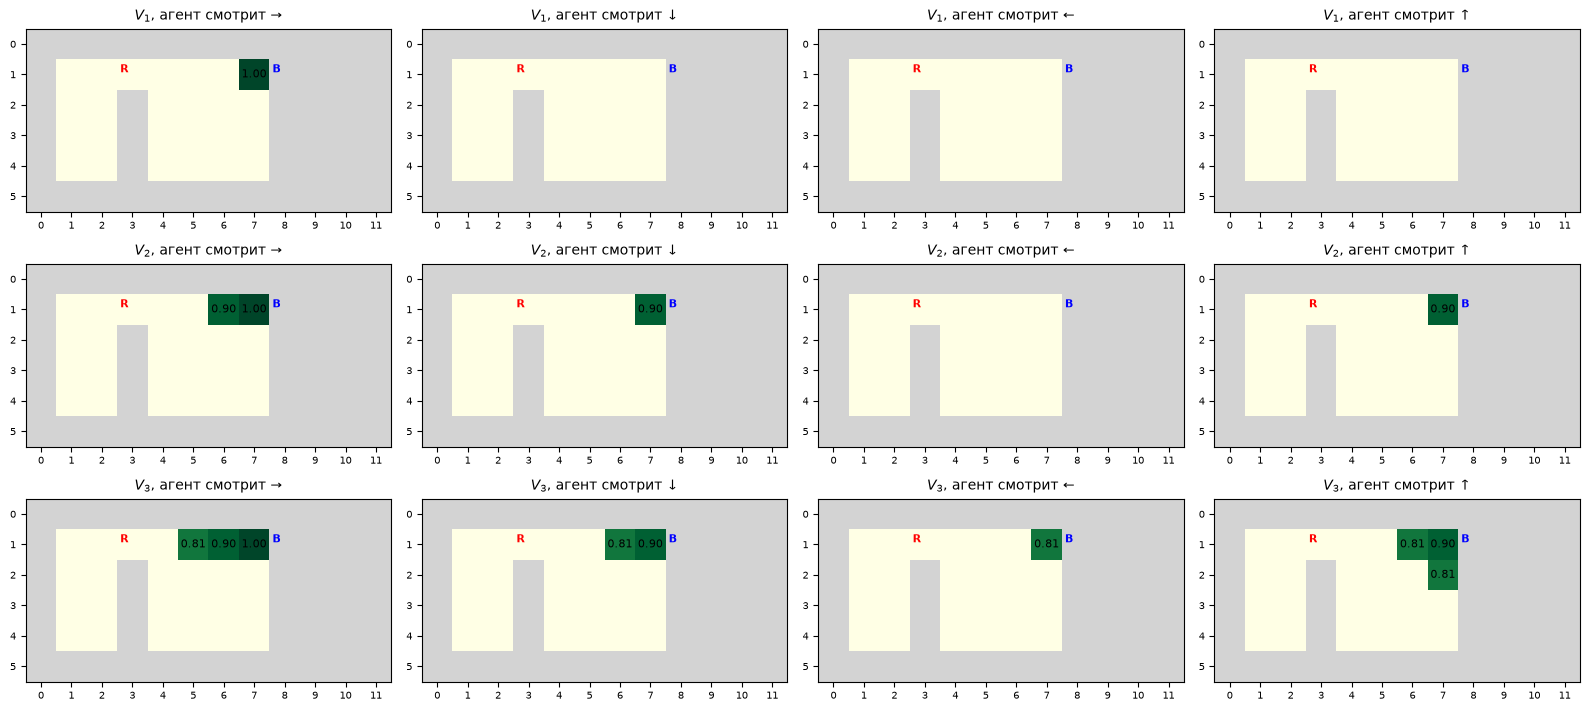

In [18]:
def plot_values(V_list, titles, states, red_open=True):
    u = next(iter(states.values())).unwrapped
    fig, axes = plt.subplots(len(V_list), 4, figsize=(16, 2.4 * len(V_list)))
    axes = np.atleast_2d(axes)
    cmap = plt.get_cmap("YlGn").copy()
    cmap.set_bad("lightgrey")
    for row, (V, title) in enumerate(zip(V_list, titles)):
        for d in range(4):
            grid = np.full((u.height, u.width), np.nan)
            for k, e in states.items():
                (x, y), arrow, is_open = describe(e)
                if is_open == red_open and e.unwrapped.agent_dir == d:
                    grid[y, x] = V.get(k, 0)
            ax = axes[row, d]
            ax.imshow(grid, cmap=cmap, vmin=0, vmax=1)
            for (y, x), v in np.ndenumerate(grid):
                if not np.isnan(v) and v > 0:
                    ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=8)
            # подписи дверей (координаты карты сида 0) — в углу клетки, чтобы не закрывать значение
            ax.text(2.6, 0.65, "R", ha="left", va="top", color="red", fontweight="bold", fontsize=8)
            ax.text(7.6, 0.65, "B", ha="left", va="top", color="blue", fontweight="bold", fontsize=8)
            ax.set_title(f"{title}, агент смотрит {'→↓←↑'[d]}", fontsize=10)
            ax.set_xticks(range(u.width))
            ax.set_yticks(range(u.height))
            ax.tick_params(labelsize=7)
    plt.tight_layout()
    plt.show()


plot_values(history, ["$V_1$", "$V_2$", "$V_3$"], states)

На картинках видно, что ценность появляется у синей двери (`B`) и с каждой итерацией расходится на одну клетку или один поворот назад. При этом значения на «волне» уменьшаются в $\gamma$ раз за шаг: 1 → 0.9 → 0.81.

### Итоги пункта 2

1. Среда детерминированная, поэтому уравнение Беллмана сводится к $V_{i+1}(s) = \max_a [r + \gamma V_i(s')]$ без мат. ожидания. Терминальные состояния имеют $V = 0$.
2. При $\gamma = 0.9$ и $V_0 = 0$:
   - $V_1$ ненулевое только у S\* (перед синей дверью, лицом к ней, красная открыта), $V_1 = 1$;
   - $V_2$ добавляет 3 соседних состояния со значением 0.9;
   - $V_3$ добавляет ещё 5 со значением 0.81.
3. **Ответ:** $V_3 \neq 0$ у 9 состояний (для синей двери в средней строке — у 10), все с открытой красной дверью. Значения $1$, $\gamma$, $\gamma^2$ соответствуют 1, 2 и 3 шагам до успеха.
4. Общий закон: $V_k(s) = \gamma^{d(s)-1}$ при $d(s) \le k$. Каждая итерация продвигает фронт ценности на один шаг от финиша, поэтому для старта в 10 шагах нужно не меньше 10 итераций.
5. Ручной расчёт подтверждён программой: те же 9 состояний и значения; «пустые» действия ответ не меняют.

## Пункт 3. Метод простой итерации (value iteration)

### 3.0. Постановка и решения

Задание: на основе кода `seminar_vi.ipynb` запрограммировать метод простой итерации $V_{i+1}(s) = \max_a [r + \gamma V_i(s')]$. Пункт 2 делал 3 итерации, здесь итерируем **до сходимости**. Требования задания и как мы их выполняем:

| Требование | Как сделано |
|---|---|
| $V$ — словарь с ключом `str(image + [direction, carrying])` | `V[state_key(obs, env)]`, функция из п. 1.3 |
| отсутствующий ключ = 0 | везде `V.get(k, 0)` |
| словарь «ключ → `copy.deepcopy(env)`» | `envs[k]` — копия окружения в состоянии `k` |
| «бесконечный цикл» перебора и обновления | `while True` с выходом по сходимости (п. 3.3) |
| маленькая карта → случайные шаги из фиксированного состояния, `reset` в терминале | `explore_random` (п. 3.2) |

**Почему у нас «маленькая карта».** Для одной расстановки дверей 196 состояний (п. 1.4). Поэтому подходит первый вариант задания — обход случайными шагами. Второй вариант (от финиша назад с ограничением памяти) нужен, когда состояний миллионы.

**Зачем словарь копий.** У семинарского `mdp` есть явные вероятности переходов `mdp.get_next_states(s, a)`. У MiniGrid их нет, но среду можно скопировать и сделать шаг в копии. Копия, сохранённая для ключа `s`, и есть наша «модель»: `deepcopy(envs[s]).step(a)` возвращает $r$ и $s'$. Среда детерминированная, поэтому одного такого шага достаточно, усреднять ничего не нужно.

**Почему одна карта (сид 0).** Задание говорит «из фиксированного состояния», и это продолжение п. 2 на той же карте. Всё, что найдём, можно проверить по картинкам п. 1.5.

### 3.1. Функции по образцу семинара

Структура и имена как в `seminar_vi.ipynb`; вместо `mdp` передаётся словарь копий `envs`.

| Семинар | Здесь | Что считает |
|---|---|---|
| `get_action_value(mdp, V, s, a, γ)` | `get_action_value(envs, V, s, a, γ)` | $Q(s,a) = r + \gamma V(s')$ |
| `get_new_state_value(mdp, V, s, γ)` | `get_new_state_value(envs, V, s, γ)` | $V_{new}(s) = \max_a Q(s,a)$ |
| `get_optimal_action(mdp, V, s, γ)` | `get_optimal_action(envs, V, s, γ)` | $\arg\max_a Q(s,a)$ |

**Одно важное отличие.** `get_action_value` не только считает $Q$, но и **регистрирует новое состояние** $s'$ в `envs`, если его там ещё не было. Случайное блуждание находит не все состояния (это видно в п. 3.2), а так множество известных состояний само достраивается до замкнутого: из каждого известного состояния все переходы ведут в известные.

**Терминальные переходы.** Если шаг закончил эпизод (`terminated`), возвращаем просто $r$: у терминального состояния $V = 0$, будущего нет (п. 2.0). `truncated` (лимит 720 шагов) не учитываем: это внешнее ограничение по времени, а не свойство состояния (п. 1.7).

In [19]:
import random


def get_action_value(envs, V, s, a, gamma):
    # Q(s, a) = r + gamma * V(s'); s' получаем шагом в копии окружения
    e = copy.deepcopy(envs[s])
    obs_next, r, terminated, truncated, _ = e.step(a)
    if terminated:
        return r  # у терминального состояния V = 0
    s_next = state_key(obs_next, e)
    if s_next not in envs:
        envs[s_next] = e  # новое состояние — запоминаем его копию
    return r + gamma * V.get(s_next, 0)


def get_q_values(envs, V, s, gamma):
    return {a: get_action_value(envs, V, s, a, gamma) for a in USEFUL_ACTIONS}


def get_new_state_value(envs, V, s, gamma):
    return max(get_q_values(envs, V, s, gamma).values())


def get_optimal_action(envs, V, s, gamma):
    q = get_q_values(envs, V, s, gamma)
    return max(q, key=q.get)  # при равенстве — первое действие в USEFUL_ACTIONS

### 3.2. Обход состояний случайными шагами

Как в задании: стартуем из фиксированного состояния (`reset(seed=SEED)`), делаем случайные действия и запоминаем копию среды для каждого нового ключа. Если эпизод закончился (успех, провал или лимит шагов), снова `reset(seed=SEED)`.

Сначала посмотрим, **сколько шагов нужно**, чтобы найти все 196 состояний (число из BFS в п. 1.4).

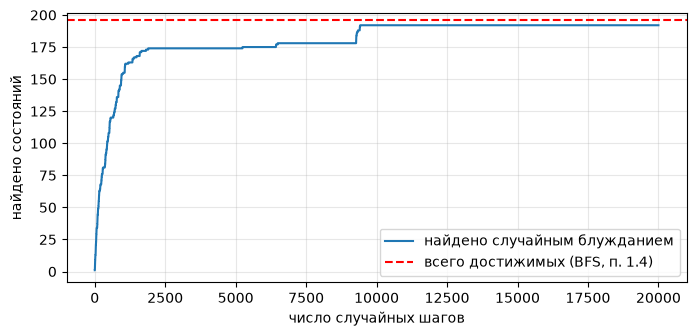

после  1000 шагов найдено 154 состояний из 196
после  5000 шагов найдено 174 состояний из 196
после 10000 шагов найдено 192 состояний из 196
после 20000 шагов найдено 192 состояний из 196


In [20]:
def explore_random(env, n_steps, seed=SEED, rng_seed=0):
    # Случайное блуждание; возвращает {ключ: копия окружения} и кривую «найдено состояний после t шагов»
    rng = random.Random(rng_seed)
    envs = {}
    curve = []
    obs, _ = env.reset(seed=seed)
    for _ in range(n_steps):
        k = state_key(obs, env)
        if k not in envs:
            envs[k] = copy.deepcopy(env)
        curve.append(len(envs))
        obs, r, terminated, truncated, _ = env.step(rng.choice(USEFUL_ACTIONS))
        if terminated or truncated:
            obs, _ = env.reset(seed=seed)
    return envs, curve


env = make_env()
_, curve = explore_random(env, 20000)
plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(1, len(curve) + 1), curve, label="найдено случайным блужданием")
plt.axhline(196, color="red", linestyle="--", label="всего достижимых (BFS, п. 1.4)")
plt.xlabel("число случайных шагов")
plt.ylabel("найдено состояний")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
for n in [1000, 5000, 10000, 20000]:
    print(f"после {n:5d} шагов найдено {curve[n - 1]} состояний из 196")

**Что видно на графике.** Большую часть состояний блуждание находит быстро, но потом кривая выходит на «полки», и последние состояния находятся очень долго. Это **редкие состояния**: до них случайно трудно добраться, нужна точная цепочка действий. Например, «выйти в коридор и закрыть красную дверь за собой» или «стоять в проёме двери». Ещё одна причина: успех или провал обрывает блуждание и возвращает агента на старт.

**Вывод.** Одно лишь блуждание надёжно все состояния не найдёт. Поэтому делаем короткое блуждание (5000 шагов), а остальное достраивается в ходе value iteration: `get_action_value` регистрирует каждое новое $s'$.

### 3.3. Цикл value iteration

Схема как в семинаре (`value_iteration`):

1. **Синхронное обновление.** На итерации $i$ считаем $V_{i+1}(s)$ для всех известных состояний по *старому* словарю $V_i$, затем заменяем словарь целиком.
2. **`diff`** — максимальное изменение $|V_{i+1}(s) - V_i(s)|$ за итерацию.
3. **Выход из `while True`** при двух условиях одновременно:
   - `diff < min_difference` — значения перестали меняться;
   - за итерацию не появилось **новых** состояний. Новое состояние стартует с $V = 0$, и пока его значение не уточнено, соседи тоже могут измениться.
4. **`max_iter`** — предохранитель от бесконечного цикла при ошибке. Если сработал он, а не сходимость, печатаем предупреждение.

Почему синхронно: так в семинаре и в п. 2, и так легко отслеживать «волну». Асинхронный вариант (обновлять $V(s)$ прямо по ходу блуждания, в посещённом состоянии) тоже сходится к тому же $V^*$, если все состояния посещаются бесконечно часто. Но сходится он медленнее и зависит от порядка посещений.

In [21]:
def value_iteration(envs, start_key, gamma=GAMMA, min_difference=1e-5, max_iter=1000):
    V = {}
    i = 0
    while True:
        i += 1
        known = list(envs)  # фиксируем список: в ходе итерации envs может пополниться
        new_V = {s: get_new_state_value(envs, V, s, gamma) for s in known}
        diff = max(abs(new_V[s] - V.get(s, 0)) for s in known)
        V = new_V
        n_new = len(envs) - len(known)
        print(f"iter {i:3d} | известно состояний: {len(known):3d} (+{n_new}) | diff: {diff:.5f} | V(старт): {V.get(start_key, 0):.4f}")
        if diff < min_difference and n_new == 0:
            print("Сошлось.")
            return V
        if i >= max_iter:
            print("ВНИМАНИЕ: достигнут max_iter, сходимости нет")
            return V


env = make_env()
envs, _ = explore_random(env, 5000)
print("Найдено блужданием:", len(envs), "состояний\n")
obs, _ = env.reset(seed=SEED)
START_KEY = state_key(obs, env)
V_star = value_iteration(envs, START_KEY)
print("\nВсего состояний в словаре:", len(envs))

Найдено блужданием: 174 состояний



iter   1 | известно состояний: 174 (+7) | diff: 1.00000 | V(старт): 0.0000


iter   2 | известно состояний: 181 (+4) | diff: 0.90000 | V(старт): 0.0000


iter   3 | известно состояний: 185 (+6) | diff: 0.81000 | V(старт): 0.0000
iter   4 | известно состояний: 191 (+4) | diff: 0.72900 | V(старт): 0.0000


iter   5 | известно состояний: 195 (+1) | diff: 0.65610 | V(старт): 0.0000


...

iter  13 | известно состояний: 196 (+0) | diff: 0.28243 | V(старт): 0.3874


iter  14 | известно состояний: 196 (+0) | diff: 0.25419 | V(старт): 0.3874


iter  15 | известно состояний: 196 (+0) | diff: 0.22877 | V(старт): 0.3874


iter  16 | известно состояний: 196 (+0) | diff: 0.20589 | V(старт): 0.3874


iter  17 | известно состояний: 196 (+0) | diff: 0.00000 | V(старт): 0.3874
Сошлось.

Всего состояний в словаре: 196


**Как читать лог.**

- **Первые итерации:** число известных состояний растёт (`+N`), так `get_action_value` достраивает то, что пропустило блуждание. После этого множество замкнуто и не меняется.
- **`diff` убывает как $0.9^{i-1}$:** 1, 0.9, 0.81, … Это «волна» из п. 2.4. На итерации $i$ ценность впервые получают состояния на расстоянии $i$ шагов от успеха, и их значение $\gamma^{i-1}$ и есть максимальное изменение.
- **V(старт) нулевая до 10-й итерации,** потом $0.9^9 \approx 0.387$, потому что от старта до успеха 10 шагов.
- **На последней итерации `diff` = 0:** все состояния уже получили точные значения. Самое далёкое состояние находится в 16 шагах, поэтому нужно 16 итераций «волны» плюс одна, чтобы убедиться, что ничего не меняется.

В детерминированной задаче с единственной наградой VI даёт **точное** решение за конечное число итераций, а не только приближённое.

### 3.4. Проверка результата

1. **Независимая проверка.** Решаем ту же задачу другим путём: все состояния берём из BFS (п. 1.4), таблицу переходов — из п. 2 (`build_transitions`), итерации — `bellman_sweep` до сходимости. Множества состояний и значения должны совпасть.
2. **Ценность старта** должна быть ровно $\gamma^9$: 10 шагов (п. 1.5).
3. **Расстояния.** Из закона $V^*(s) = \gamma^{d(s)-1}$ восстанавливаем $d(s) = 1 + \log V^*(s) / \log \gamma$ — минимальное число шагов до успеха — и смотрим, сколько состояний на каждом расстоянии.

In [22]:
states_bfs, _ = reachable_states(env, obs)
T_bfs = build_transitions(states_bfs, USEFUL_ACTIONS)
V_check = {}
while True:
    new_V = bellman_sweep(V_check, states_bfs, T_bfs, USEFUL_ACTIONS, GAMMA)
    if all(abs(new_V[s] - V_check.get(s, 0)) < 1e-12 for s in states_bfs):
        break
    V_check = new_V

assert set(V_star) == set(states_bfs), "множества состояний различаются"
assert all(np.isclose(V_star[s], V_check[s]) for s in states_bfs), "значения различаются"
print("Совпадает с независимой проверкой: те же", len(states_bfs), "состояний и те же значения V*")

assert np.isclose(V_star[START_KEY], GAMMA ** 9)
print(f"V*(старт) = {V_star[START_KEY]:.4f} = 0.9^9 -> до успеха 10 шагов")

dist = {s: int(round(1 + np.log(v) / np.log(GAMMA))) for s, v in V_star.items()}
counts = Counter(dist.values())
print("\nРасстояние до успеха d -> число состояний:")
print({d: counts[d] for d in sorted(counts)})
far = max(dist, key=dist.get)
print("Самое далёкое состояние:", describe(envs[far]), "d =", dist[far], f"V* = {V_star[far]:.4f}")

Совпадает с независимой проверкой: те же 196 состояний и те же значения V*
V*(старт) = 0.3874 = 0.9^9 -> до успеха 10 шагов

Расстояние до успеха d -> число состояний:
{1: 1, 2: 3, 3: 5, 4: 8, 5: 12, 6: 15, 7: 17, 8: 18, 9: 18, 10: 21, 11: 25, 12: 23, 13: 16, 14: 9, 15: 4, 16: 1}
Самое далёкое состояние: ((7, 4), '↓', False) d = 16 V* = 0.2059


### 3.5. Наглядно: $V^*$ на карте

Те же тепловые карты, что в п. 2.6 (`plot_values`), но теперь для сошедшегося $V^*$ и для обоих случаев: красная дверь закрыта и открыта.

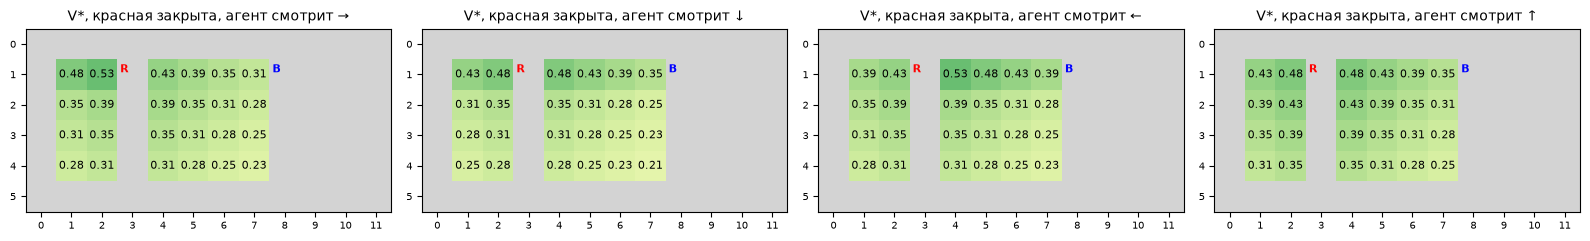

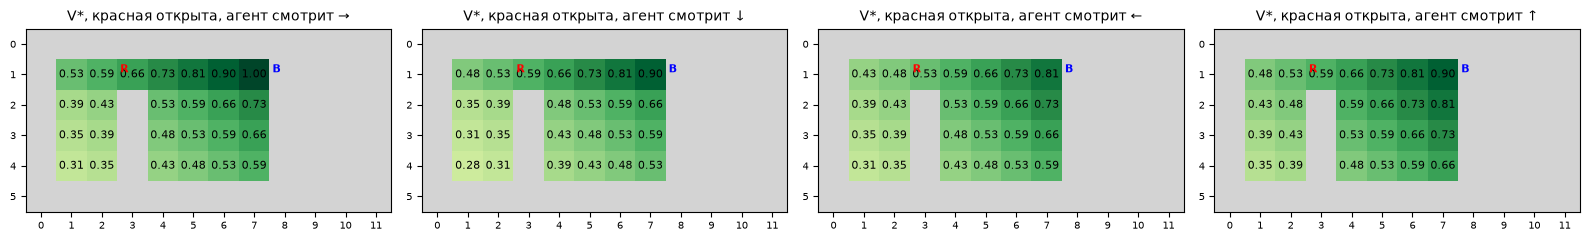

In [23]:
plot_values([V_star], ["V*, красная закрыта"], envs, red_open=False)
plot_values([V_star], ["V*, красная открыта"], envs, red_open=True)

**Что видно.**

- **Красная закрыта:** ценность растёт к красной двери (`R`), а не к синей. Агенту сначала нужно идти открывать красную. Клетки у синей двери здесь имеют *меньшую* ценность, чем у красной, хотя до синей ближе. Состояния в левом коридоре (агент закрыл дверь за собой) тоже ценны: красная рядом, её нужно лишь снова открыть.
- **Красная открыта:** ценность растёт к синей двери (`B`). Максимум 1.00 — в клетке перед ней, лицом к двери.
- **Направление имеет значение.** В одной клетке ценность различается в зависимости от того, куда смотрит агент: каждый лишний поворот — лишний шаг, то есть множитель $\gamma$.

### 3.6. Оптимальная Q-функция в близких и далёких состояниях

По заданию выводим $Q^*(s, a) = r + \gamma V^*(s')$ для всех действий в состояниях на разном расстоянии от финиша. $V^*(s) = \max_a Q^*(s,a)$, лучшее действие — $\arg\max$.

Выбранные состояния:
- **S\*** — у самой синей двери;
- **шаг до S\*** — на соседней клетке;
- **ловушка** — та же клетка, что S\*, но красная дверь закрыта;
- **старт** сида 0;
- **левый коридор, дверь закрыта** — агент вышел и закрыл красную за собой;
- **самое далёкое** состояние.

In [24]:
import pandas as pd

key_by_desc = {describe(e): k for k, e in envs.items()}
examples = [
    ("S*: перед синей, красная открыта", ((7, 1), "→", True)),
    ("шаг до S*", ((6, 1), "→", True)),
    ("ловушка: перед синей, красная закрыта", ((7, 1), "→", False)),
    ("старт сида 0", ((6, 1), "↓", False)),
    ("коридор, закрыл красную за собой", ((2, 1), "→", False)),
    ("самое далёкое", describe(envs[far])),
]
rows = []
for name, d in examples:
    k = key_by_desc[d]
    q = get_q_values(envs, V_star, k, GAMMA)
    best = max(q.values())
    rows.append({
        "состояние": name,
        "(x, y) dir, красная": f"{d[0]} {d[1]}, {'откр.' if d[2] else 'закр.'}",
        **{f"Q({ACTION_NAMES[a]})": round(v, 4) for a, v in q.items()},
        "V* = max Q": round(best, 4),
        "лучшие действия": ", ".join(ACTION_NAMES[a] for a, v in q.items() if np.isclose(v, best)),
        "d (шагов)": dist[k],
    })
q_table = pd.DataFrame(rows).set_index("состояние")
q_table

,"(x, y) dir, красная",Q(left),Q(right),Q(forward),Q(toggle),V* = max Q,лучшие действия,d (шагов)
состояние,,,,,,,,
"S*: перед синей, красная открыта","(7, 1) →, откр.",0.8100,0.8100,0.9000,1.0000,1.0000,toggle,1
шаг до S*,"(6, 1) →, откр.",0.7290,0.7290,0.9000,0.8100,0.9000,forward,2
"ловушка: перед синей, красная закрыта","(7, 1) →, закр.",0.3138,0.3138,0.2824,0.0000,0.3138,"left, right",12
старт сида 0,"(6, 1) ↓, закр.",0.3138,0.3874,0.2542,0.3487,0.3874,right,10
"коридор, закрыл красную за собой","(2, 1) →, закр.",0.4305,0.4305,0.4783,0.5314,0.5314,toggle,7
самое далёкое,"(7, 4) ↓, закр.",0.2059,0.2059,0.1853,0.1853,0.2059,"left, right",16


**Разбор строк.**

- **S\*, d = 1.** `toggle` открывает синюю дверь при открытой красной: $Q = 1$. Любое другое действие уводит от цели, и значение ниже: например, `left` даёт $0.9 \cdot V^*(7,1,↑) = 0.9 \cdot 0.9 = 0.81$. `forward` упирается в закрытую дверь, агент остаётся на месте: $Q = 0.9 \cdot V^*(S^*) = 0.9$. Это ещё и пример того, что «пустое» действие стоит ровно $\gamma V(s)$.
- **Шаг до S\*, d = 2.** Лучшее действие `forward`: $Q = 0.9 \cdot 1 = 0.9$.
- **Ловушка.** Агент в той же клетке, что и S\*, но красная закрыта. $Q(\text{toggle}) = 0$: открытие синей сейчас — провал, эпизод закончится без награды. Остальные $Q > 0$: VI «знает», что сначала нужно вернуться к красной двери. Отсюда $d = 12$: развернуться (2), дойти до красной (3), открыть (1), развернуться (2), вернуться (3), открыть синюю (1). Без полного наблюдения (п. 1.3) эти два состояния слились бы в одно, и правильно действовать было бы невозможно.
- **Старт, d = 10.** Лучшее действие `right` — повернуться к красной двери. $V^* = 0.9^9$, как и должно быть.
- **Коридор с закрытой дверью.** Лучшее действие `toggle` — снова открыть красную. Сам по себе выход в коридор бесполезен, но если агент там оказался, VI даёт ему правильное продолжение.
- **Самое далёкое, d = 16.** Агент в нижнем правом углу комнаты, смотрит вниз, красная закрыта: максимальное расстояние и до красной двери, и потом до синей.

**Если у двух действий одинаковое $Q$,** значит, есть два одинаково коротких пути. Так в строках «ловушка» и «самое далёкое»: `left` и `right` равны, потому что разворот на 180° можно начать в любую сторону, а дальше пути одинаковой длины. Политика может выбрать любое; `get_optimal_action` берёт первое.

### 3.7. Жадная политика по $V^*$

Последняя проверка: из старта сида 0 в каждом состоянии выбираем `get_optimal_action` и смотрим, что получится. Оптимальная политика должна дойти до успеха за минимальные 10 шагов (п. 1.5).

Жадная политика: ['right', 'forward', 'forward', 'toggle', 'left', 'left', 'forward', 'forward', 'forward', 'toggle']
шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | forward  | 0.0000 | False | False
  9 | forward  | 0.0000 | False | False
 10 | toggle   | 1.0000 | True  | False
Суммарная награда: 1


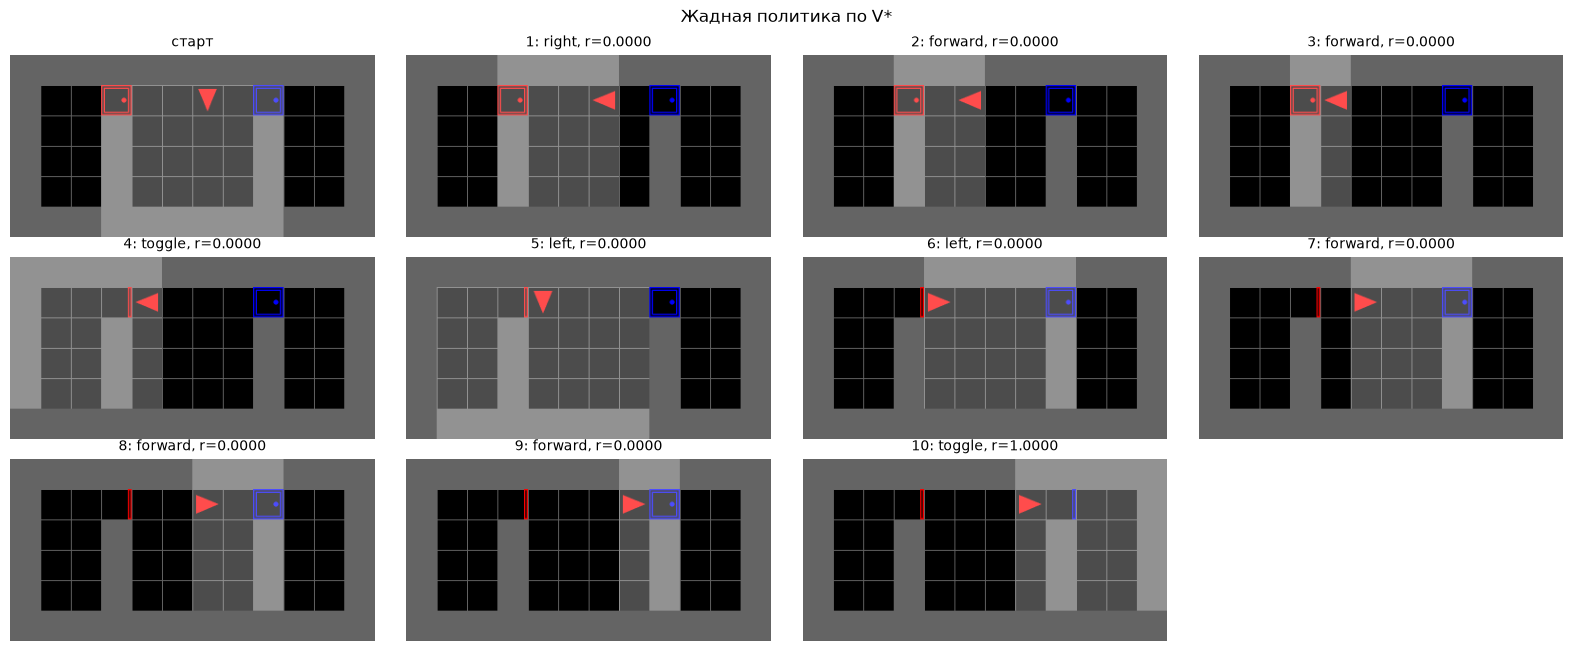

In [25]:
env = make_env()
obs, _ = env.reset(seed=SEED)
greedy_actions = []
for _ in range(50):  # предохранитель: оптимальный путь — 10 шагов
    a = get_optimal_action(envs, V_star, state_key(obs, env), GAMMA)
    greedy_actions.append(a)
    obs, r, terminated, truncated, _ = env.step(a)
    if terminated or truncated:
        break
print("Жадная политика:", [ACTION_NAMES[a] for a in greedy_actions])
total = run_actions(env, greedy_actions, title="Жадная политика по V*")
assert total == 1 and len(greedy_actions) == 10

Политика открыла красную, затем синюю дверь за 10 шагов, награда 1. Это тот же путь, что мы нашли вручную в п. 1.5. Value iteration «сам» нашёл оптимальное решение.

### Итоги пункта 3

1. Метод простой итерации запрограммирован по образцу семинара (`get_action_value`, `get_new_state_value`, `get_optimal_action`, `value_iteration`). Вместо явной модели `mdp` используется словарь копий окружения: $s'$ получаем шагом в `deepcopy`.
2. Состояния перебираются, как предлагает задание для маленькой карты: случайным блужданием из фиксированного старта с `reset` в терминале. Блуждание пропускает редкие состояния, поэтому `get_action_value` регистрирует каждое новое $s'$, и множество за несколько итераций достраивается до всех 196.
3. «Бесконечный» цикл `while True` выходит, когда `diff < min_difference` и новых состояний нет. Сошлось за 17 итераций. `diff` убывал как $0.9^{i-1}$, то есть ценность распространялась «волной» от финиша (п. 2.4).
4. Результат точный: $V^*(s) = \gamma^{d(s)-1}$. Он совпал с независимой проверкой по BFS. $V^*(\text{старт}) = 0.9^9$ (10 шагов), самое далёкое состояние — 16 шагов.
5. Q-функция осмысленна:
   - у финиша лучшее действие `toggle` ($Q = 1$);
   - в «ловушке» с закрытой красной `toggle` даёт 0, и агент идёт к красной двери;
   - с закрытой красной ценность растёт к красной двери, с открытой — к синей.
6. Жадная политика по $V^*$ решает задачу за минимальные 10 шагов.

## Пункт 4. Метод кросс-энтропии

### 4.0. Постановка и решения

Задание: на основе `crossentropy_method.ipynb` запрограммировать метод кросс-энтропии (CEM) для нашей игры, обучить и добиться сходимости.

**Идея CEM на пальцах.** Политика — таблица вероятностей $\pi(a \mid s)$: в каждом состоянии с какой вероятностью какое действие выбирать. Одна итерация:

1. сыграть много эпизодов текущей политикой;
2. отобрать лучшие эпизоды — **элиту** (выше перцентиля по награде);
3. новая политика = как часто в элитных эпизодах в состоянии $s$ выбиралось действие $a$;
4. повторить.

Политика постепенно «копирует» удачные эпизоды и становится всё более уверенной.

**Чем это отличается от п. 3.**

| | Value iteration (п. 3) | CEM (п. 4) |
|---|---|---|
| Модель среды | нужна: шаги в копиях `deepcopy(env)` из любого состояния | не нужна: только играем эпизоды со старта |
| Что учим | ценности $V(s)$, политика — жадная по ним | сразу политику $\pi(a \mid s)$ |
| Какие состояния знаем | все 196 | только те, что встречаются в эпизодах |

**Адаптация шаблона.**

- **Состояния → номера.** В шаблоне политика — массив `[n_states, n_actions]`, а состояния Taxi — числа. У нас состояние — строка `state_key`. Нумеруем 196 ключей из словаря `envs` пункта 3: `state_index[key] = номер строки`. Множество замкнуто (п. 3.3), поэтому новых ключей в эпизодах не будет.
- **Действия.** Только 4 полезных (`USEFUL_ACTIONS`, п. 1.2). Столбец политики $j$ ↔ действие среды `USEFUL_ACTIONS[j]`. Бесполезные действия лишь удлиняли бы случайные эпизоды.
- **Старт.** `reset(seed=SEED)` — та же карта сида 0, что во всей лабе. Поэтому проблема из ячейки шаблона «Reflecting on results» (у Taxi старт случайный, и политика «забывает» неудачные стартовые позиции) здесь не возникает: старт всегда один.

### 4.1. Начальная политика

Как в шаблоне: **равномерная**, все 4 действия с вероятностью 1/4. Мы ничего не знаем об игре, поэтому никакое действие не предпочитаем.

In [26]:
state_index = {k: i for i, k in enumerate(envs)}  # ключ состояния -> номер строки политики
n_states, n_actions = len(state_index), len(USEFUL_ACTIONS)
print(f"n_states={n_states}, n_actions={n_actions}")


def initialize_policy(n_states, n_actions):
    policy = np.full((n_states, n_actions), 1.0 / n_actions)
    return policy


policy = initialize_policy(n_states, n_actions)

assert type(policy) in (np.ndarray, np.matrix)
assert np.allclose(policy, 1.0 / n_actions)
assert np.allclose(np.sum(policy, axis=1), 1)

n_states=196, n_actions=4


### 4.2. Игра одного эпизода

`generate_session` как в шаблоне: сэмплируем действие из $\pi(\cdot \mid s)$, запоминаем номера состояний и действий. Одно изменение — **награда эпизода дисконтированная**:

$$G = \sum_t \gamma^t r_t, \qquad \gamma = 0.9$$

Награда 1 бывает только в последний шаг успеха, поэтому при успехе за $T$ шагов $G = 0.9^{T-1}$, а при провале $G = 0$. Почему так, а не просто сумма наград — в 4.3.

Генератор случайных чисел `rng` передаём явно, чтобы обучение было воспроизводимым.

In [27]:
rng = np.random.default_rng(SEED)


def generate_session(env, policy, t_max=10**4, rng=rng, gamma=GAMMA):
    states, actions = [], []
    total_reward = 0.0

    s, _ = env.reset(seed=SEED)

    for t in range(t_max):
        s_i = state_index[state_key(s, env)]
        a = rng.choice(n_actions, p=policy[s_i])

        new_s, r, terminated, truncated, _ = env.step(USEFUL_ACTIONS[a])

        states.append(s_i)
        actions.append(a)
        total_reward += gamma**t * r  # дисконтированная награда: короткий успех ценнее длинного

        s = new_s
        if terminated or truncated:
            break

    return states, actions, total_reward


env = make_env()
s, a, r = generate_session(env, policy)
assert type(s) == type(a) == list
assert len(s) == len(a)
assert type(r) in [float, np.float64]

**Как играет случайная политика.** Как ячейка с гистограммой в шаблоне: 200 эпизодов равномерной политикой, смотрим долю успехов и длину эпизодов.

Успехов: 18%
Средняя длина успешного эпизода: 362 шагов (оптимум — 10)
Самый короткий успех: 65 шагов


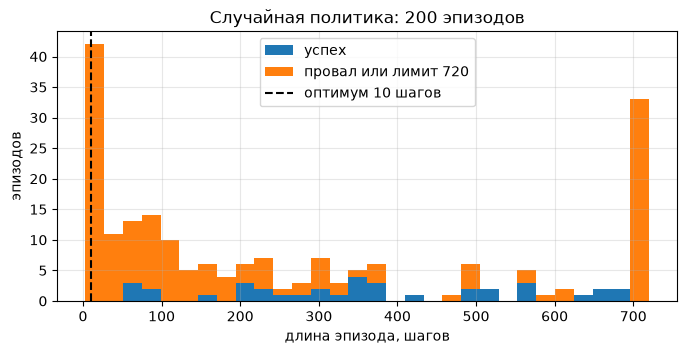

In [28]:
sample = [generate_session(env, policy) for _ in range(200)]
lengths = np.array([len(s) for s, _, _ in sample])
wins = np.array([g > 0 for _, _, g in sample])
print(f"Успехов: {wins.mean():.0%}")
print(f"Средняя длина успешного эпизода: {lengths[wins].mean():.0f} шагов (оптимум — 10)")
print(f"Самый короткий успех: {lengths[wins].min()} шагов")

plt.figure(figsize=(8, 3.5))
plt.hist([lengths[wins], lengths[~wins]], bins=30, stacked=True, label=["успех", "провал или лимит 720"])
plt.axvline(10, color="black", ls="--", label="оптимум 10 шагов")
plt.xlabel("длина эпизода, шагов")
plt.ylabel("эпизодов")
plt.title("Случайная политика: 200 эпизодов")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Что видим.** Случайная политика иногда побеждает (около 20% эпизодов), но очень долго, сотни шагов. Провалы бывают короткими: агент случайно открывает синюю дверь раньше красной. Это хорошая стартовая точка для CEM: успешные эпизоды есть, есть из чего выбирать элиту.

### 4.3. Почему награду нужно дисконтировать

В шаблоне эпизоды сравниваются по сумме наград. У нас после `BinaryRewardWrapper` сумма наград эпизода — **0 или 1**. Отсюда две проблемы.

**Проблема 1: элитой становятся все.** Порог элиты — перцентиль наград, а в элиту попадают эпизоды с наградой `>=` порога. Если успехов меньше половины, то перцентиль 50 от набора «80% нулей, 20% единиц» равен **0**, и условие `награда >= 0` выполнено для всех эпизодов. Политика учится на всех подряд, то есть копирует случайное поведение, и ничего не меняется.

**Решение:** в элиту берём только успешные эпизоды (`награда > 0`). Проигранный эпизод не может быть «лучшим», даже если порог 0.

**Проблема 2: все успехи одинаковы.** Успех за 10 шагов и успех за 500 шагов оба дают 1. CEM не видит разницы и выучит **какой-нибудь** путь к победе, но не короткий.

**Решение:** оцениваем эпизод дисконтированной наградой $G = 0.9^{T-1}$. Чем короче успех, тем больше $G$, и перцентиль отбирает самые короткие.

Это та же величина, что в п. 2–3: $V^*(s)$ — это максимальная дисконтированная награда из $s$. Поэтому CEM оптимизирует ту же цель, что value iteration, и результаты можно напрямую сравнить: лучшее возможное $G$ со старта равно $V^*(\text{старт}) = 0.9^9 \approx 0.387$.

Оба решения проверяются экспериментом в 4.8.

### 4.4. Отбор элиты

`select_elites` по шаблону: порог через `np.percentile`, сравнение `>=`. Добавлен флаг `only_success` из 4.3: при `True` эпизоды с нулевой наградой в элиту не попадают. Флаг нужен только для сравнения в 4.8, в обучении он всегда `True`.

Тесты шаблона проходят без изменений: в них все награды положительные. Добавлен тест на бинарные награды.

In [29]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile, only_success=True):
    reward_threshold = np.percentile(rewards_batch, percentile)

    elite = [i for i, r in enumerate(rewards_batch) if r >= reward_threshold and (r > 0 or not only_success)]
    elite_states = [s for i in elite for s in states_batch[i]]
    elite_actions = [a for i in elite for a in actions_batch[i]]

    return elite_states, elite_actions


# тесты из шаблона
states_batch = [[1, 2, 3], [4, 2, 0, 2], [3, 1]]
actions_batch = [[0, 2, 4], [3, 2, 0, 1], [3, 3]]
rewards_batch = [3, 4, 5]

test_result_0 = select_elites(states_batch, actions_batch, rewards_batch, percentile=0)
test_result_30 = select_elites(states_batch, actions_batch, rewards_batch, percentile=30)
test_result_90 = select_elites(states_batch, actions_batch, rewards_batch, percentile=90)
test_result_100 = select_elites(states_batch, actions_batch, rewards_batch, percentile=100)

assert np.all(test_result_0[0] == [1, 2, 3, 4, 2, 0, 2, 3, 1]) and np.all(test_result_0[1] == [0, 2, 4, 3, 2, 0, 1, 3, 3])
assert np.all(test_result_30[0] == [4, 2, 0, 2, 3, 1]) and np.all(test_result_30[1] == [3, 2, 0, 1, 3, 3])
assert np.all(test_result_90[0] == [3, 1]) and np.all(test_result_90[1] == [3, 3])
assert np.all(test_result_100[0] == [3, 1]) and np.all(test_result_100[1] == [3, 3])

# наш случай: бинарные награды, успешен только 3-й эпизод, порог-перцентиль 50 равен 0
binary = [0, 0, 1]
assert select_elites(states_batch, actions_batch, binary, 50, only_success=False)[0] == [1, 2, 3, 4, 2, 0, 2, 3, 1]  # элита — все
assert select_elites(states_batch, actions_batch, binary, 50)[0] == [3, 1]  # элита — только успех
print("Ok!")

Ok!


### 4.5. Новая политика по элите

`get_new_policy` по шаблону: $\pi_{\text{new}}(a \mid s) = \dfrac{\#(s, a) \text{ в элите}}{\#s \text{ в элите}}$. Для состояний, которых нет в элите, — равномерное распределение: о них мы ничего не узнали.

Тест шаблона написан для Taxi с 6 действиями (в нём встречается действие 4), поэтому в тесте передаём `n_actions=6`.

In [30]:
def get_new_policy(elite_states, elite_actions, n_states=n_states, n_actions=n_actions):
    new_policy = np.zeros([n_states, n_actions])

    np.add.at(new_policy, (elite_states, elite_actions), 1)  # счётчики пар (s, a)
    visited = new_policy.sum(axis=1) > 0
    new_policy[visited] /= new_policy[visited].sum(axis=1, keepdims=True)
    new_policy[~visited] = 1.0 / n_actions  # непосещённые состояния — равномерно

    return new_policy


# тест из шаблона
elite_states = [1, 2, 3, 4, 2, 0, 2, 3, 1]
elite_actions = [0, 2, 4, 3, 2, 0, 1, 3, 3]
new_policy = get_new_policy(elite_states, elite_actions, n_actions=6)

assert np.isfinite(new_policy).all()
assert np.all(new_policy >= 0)
assert np.allclose(new_policy.sum(axis=-1), 1)
reference_answer = np.array([
    [1.0, 0.0, 0.0, 0.0, 0.0],
    [0.5, 0.0, 0.0, 0.5, 0.0],
    [0.0, 0.33333333, 0.66666667, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.5, 0.5],
])
assert np.allclose(new_policy[:4, :5], reference_answer)
print("Ok!")

Ok!


### 4.6. Цикл обучения

Цикл из шаблона, оформленный функцией `train_cem`, чтобы в 4.8 запускать его с разными настройками. Политика обновляется со сглаживанием, как в шаблоне:

$$\pi \leftarrow \alpha \cdot \pi_{\text{new}} + (1 - \alpha) \cdot \pi$$

**Параметры и почему такие.**

- `n_sessions = 250` — как в шаблоне. Эпизодов должно быть много, чтобы среди них нашлись успешные: в начале их около 20%, то есть ~50 штук.
- `percentile = 80` (в шаблоне 50). В начале успешны ~20% эпизодов, поэтому верхние 20% — это примерно «все успешные». Когда побеждать станут все, перцентиль 80 оставит 20% самых коротких успехов.
- `learning_rate` $\alpha = 0.5$ — как в шаблоне. Политика не забывает сразу всё, что знала: одна неудачная партия эпизодов не ломает выученное. При $\alpha = 1$ состояния, не попавшие в элиту, мгновенно забывались бы.
- `n_iter = 30` — с запасом: по прототипу сходимость наступает за ~20 итераций.

**Что логируем на каждой итерации:** долю успехов, среднюю длину эпизода, порог элиты, число элитных эпизодов и максимальное изменение вероятностей в политике. Последнее — **критерий сходимости**: когда политика перестаёт меняться, обучение сошлось.

In [31]:
import time


def train_cem(n_iter=30, n_sessions=250, percentile=80, learning_rate=0.5,
              score="discounted", only_success=True, seed=SEED, verbose=True):
    rng = np.random.default_rng(seed)
    env = make_env()
    policy = initialize_policy(n_states, n_actions)
    log = []
    t0 = time.time()

    for i in range(n_iter):
        sessions = [generate_session(env, policy, rng=rng) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        wins = [g > 0 for g in rewards_batch]
        if score == "binary":
            rewards_batch = [float(w) for w in wins]  # как в шаблоне: награда эпизода 0 или 1

        elite_states, elite_actions = select_elites(states_batch, actions_batch, rewards_batch, percentile, only_success)

        old_policy = policy
        if elite_states:  # ни одного элитного эпизода — политику не трогаем
            new_policy = get_new_policy(elite_states, elite_actions)
            policy = learning_rate * new_policy + (1 - learning_rate) * policy

        threshold = np.percentile(rewards_batch, percentile)
        log.append({
            "success": np.mean(wins),
            "length": np.mean([len(s) for s in states_batch]),
            "threshold": threshold,
            "mean_score": np.mean(rewards_batch),
            "n_elite": sum(r >= threshold and (r > 0 or not only_success) for r in rewards_batch),
            "delta": np.abs(policy - old_policy).max(),
        })
        if verbose:
            l = log[-1]
            print(f"iter {i + 1:2d} | успехов {l['success']:4.0%} | средняя длина {l['length']:6.1f} | "
                  f"порог {l['threshold']:.3f} | элита {l['n_elite']:3d} | max Δπ {l['delta']:.3f} | {time.time() - t0:4.0f} с")

    return policy, pd.DataFrame(log)


cem_policy, cem_log = train_cem()

iter  1 | успехов  17% | средняя длина  270.8 | порог 0.000 | элита  42 | max Δπ 0.148 |   11 с


iter  2 | успехов  56% | средняя длина  369.7 | порог 0.000 | элита  50 | max Δπ 0.390 |   27 с


iter  3 | успехов  86% | средняя длина  242.6 | порог 0.000 | элита  50 | max Δπ 0.398 |   37 с


iter  4 | успехов  98% | средняя длина  113.2 | порог 0.002 | элита  51 | max Δπ 0.447 |   42 с


iter  5 | успехов  99% | средняя длина   68.0 | порог 0.031 | элита  52 | max Δπ 0.465 |   45 с


...

iter 26 | успехов 100% | средняя длина   10.0 | порог 0.387 | элита 250 | max Δπ 0.019 |   58 с


iter 27 | успехов 100% | средняя длина   10.0 | порог 0.387 | элита 250 | max Δπ 0.002 |   59 с


iter 28 | успехов 100% | средняя длина   10.0 | порог 0.387 | элита 250 | max Δπ 0.025 |   59 с


iter 29 | успехов 100% | средняя длина   10.0 | порог 0.387 | элита 250 | max Δπ 0.017 |   60 с


iter 30 | успехов 100% | средняя длина   10.0 | порог 0.387 | элита 250 | max Δπ 0.024 |   60 с


**Как читать лог.**

- **Первые итерации:** доля успехов быстро растёт от ~20% до 100%. Эпизоды пока длинные, а порог 0: в элиту попадают все успешные (`only_success`).
- **Средние итерации:** побеждают все, и порог начинает расти. Перцентиль отбирает самые короткие успехи, и средняя длина падает с сотен шагов до десятков.
- **Последние итерации:** длина ровно 10 = оптимум из п. 3, порог $0.387 = 0.9^9 = V^*(\text{старт})$. Все 250 эпизодов — успехи за 10 шагов, у всех $G$ равен порогу, поэтому элитой становятся все. Доля успехов, длина и порог больше не меняются. **Это и есть сходимость.**
- **Почему `max Δπ` не ровно 0, а колеблется около 0.01–0.03.** На оптимальном пути есть состояние, где два действия одинаково хороши: после открытия красной двери агенту нужно развернуться, и можно начать поворот налево или направо (см. 4.9). Элита каждый раз случайно делится между этими путями, поэтому вероятность в этом состоянии слегка «гуляет». На качество это не влияет: оба пути оптимальны и дают одинаковое $G$.

### 4.7. Графики сходимости

Шаблонный `show_progress` перерисовывает график на каждой итерации. В сохранённом ноутбуке от этого остаётся только последний кадр, поэтому рисуем историю одним графиком после обучения. Три панели — три фазы обучения.

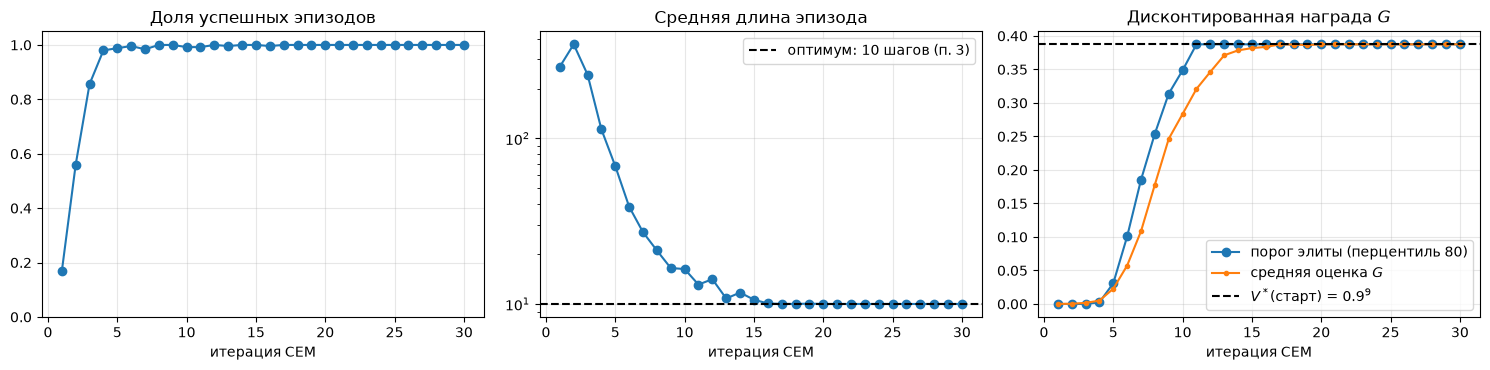

Сошлось: все эпизоды последней итерации — успех за 10 шагов, G = V*(старт) = 0.3874


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
it = np.arange(1, len(cem_log) + 1)

axes[0].plot(it, cem_log["success"], marker="o")
axes[0].set_title("Доля успешных эпизодов")
axes[0].set_ylim(0, 1.05)

axes[1].plot(it, cem_log["length"], marker="o")
axes[1].axhline(10, color="black", ls="--", label="оптимум: 10 шагов (п. 3)")
axes[1].set_yscale("log")
axes[1].set_title("Средняя длина эпизода")
axes[1].legend()

axes[2].plot(it, cem_log["threshold"], marker="o", label="порог элиты (перцентиль 80)")
axes[2].plot(it, cem_log["mean_score"], marker=".", label="средняя оценка $G$")
axes[2].axhline(V_star[START_KEY], color="black", ls="--", label="$V^*$(старт) = $0.9^9$")
axes[2].set_title("Дисконтированная награда $G$")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("итерация CEM")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

final = cem_log.iloc[-1]
assert final["success"] == 1 and final["length"] == 10
assert np.isclose(final["threshold"], V_star[START_KEY])
print("Сошлось: все эпизоды последней итерации — успех за 10 шагов, G = V*(старт) =", round(V_star[START_KEY], 4))

**Что видно.**

1. **Слева:** сначала CEM учится **побеждать** — доля успехов доходит до 100% за несколько итераций.
2. **В центре:** потом учится побеждать **быстро** — длина падает до 10 шагов. Шкала логарифмическая, потому что начальные эпизоды длиннее оптимальных в десятки раз.
3. **Справа:** порог элиты и средняя оценка выходят ровно на $V^*(\text{старт})$ из п. 3. CEM не знает модели среды и ни разу не считал $V$, но пришёл к тому же оптимуму, что value iteration.

### 4.8. Эксперимент: зачем нужны изменения из 4.3

Запускаем тот же `train_cem` в трёх вариантах (по 100 эпизодов × 15 итераций, чтобы было быстрее):

| Вариант | Оценка эпизода | Перцентиль | Проигрыш в элите |
|---|---|---|---|
| A. дословно как в шаблоне | бинарная (0/1) | 50 | может быть |
| B. только исправление проблемы 1 | бинарная (0/1) | 80 | нет |
| C. наш вариант | дисконтированная $0.9^{T-1}$ | 80 | нет |

A. шаблон: бинарная, p50                   | успехов  10% | средняя длина  223.4 |  57 с


B. бинарная, только успехи, p80            | успехов  99% | средняя длина  236.4 |  73 с


C. дисконтированная, только успехи, p80    | успехов 100% | средняя длина   10.0 |  23 с


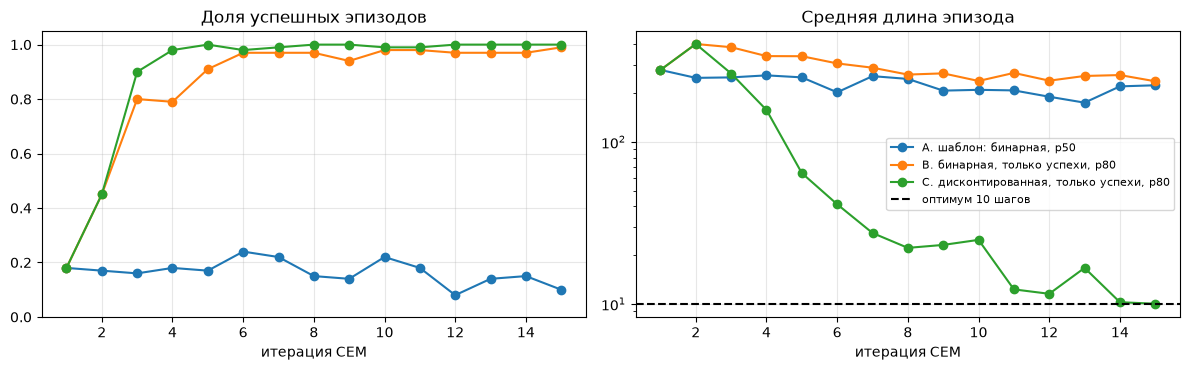

In [33]:
variants = {
    "A. шаблон: бинарная, p50": dict(score="binary", percentile=50, only_success=False),
    "B. бинарная, только успехи, p80": dict(score="binary", percentile=80, only_success=True),
    "C. дисконтированная, только успехи, p80": dict(score="discounted", percentile=80, only_success=True),
}
logs = {}
for name, kw in variants.items():
    t0 = time.time()
    _, logs[name] = train_cem(n_iter=15, n_sessions=100, verbose=False, **kw)
    l = logs[name].iloc[-1]
    print(f"{name:42s} | успехов {l['success']:4.0%} | средняя длина {l['length']:6.1f} | {time.time() - t0:3.0f} с")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, log in logs.items():
    it = np.arange(1, len(log) + 1)
    axes[0].plot(it, log["success"], marker="o", label=name)
    axes[1].plot(it, log["length"], marker="o", label=name)
axes[0].set_title("Доля успешных эпизодов")
axes[0].set_ylim(0, 1.05)
axes[1].axhline(10, color="black", ls="--", label="оптимум 10 шагов")
axes[1].set_yscale("log")
axes[1].set_title("Средняя длина эпизода")
for ax in axes:
    ax.set_xlabel("итерация CEM")
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Вывод эксперимента.**

- **A (дословно):** доля успехов не растёт и колеблется на уровне случайной политики (10–25%). Порог-перцентиль равен 0, элита — все эпизоды, и политика копирует случайное поведение. Это проблема 1 из 4.3.
- **B:** агент научился побеждать почти всегда, но длина эпизода остаётся сотни шагов. Все успехи для него одинаково хороши, поэтому короткий путь не поощряется. Это проблема 2.
- **C:** и побеждает, и выходит на оптимальные 10 шагов.

Значит, оба изменения шаблона необходимы: без первого обучения нет вообще, без второго нет оптимальности.

### 4.9. Проверка результата

**Жадная политика.** В каждом состоянии берём самое вероятное действие (`argmax` по строке политики) и играем со старта. На каждом шаге сверяемся с п. 3: действие CEM должно быть одним из оптимальных по $Q^*$. При равных $Q^*$ (например, разворот налево или направо) оптимальных действий несколько, и подходит любое.

шаг | состояние                | действие CEM | π(a|s) | оптимальные по Q* (п. 3)
  1 | (6, 1) ↓ красная закр.  | right        |  1.000 | right
  2 | (6, 1) ← красная закр.  | forward      |  1.000 | forward
  3 | (5, 1) ← красная закр.  | forward      |  1.000 | forward
  4 | (4, 1) ← красная закр.  | toggle       |  1.000 | toggle
  5 | (4, 1) ← красная откр.  | left         |  0.628 | left, right
  6 | (4, 1) ↓ красная откр.  | left         |  1.000 | left
  7 | (4, 1) → красная откр.  | forward      |  1.000 | forward
  8 | (5, 1) → красная откр.  | forward      |  1.000 | forward
  9 | (6, 1) → красная откр.  | forward      |  1.000 | forward
 10 | (7, 1) → красная откр.  | toggle       |  1.000 | toggle
шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
 

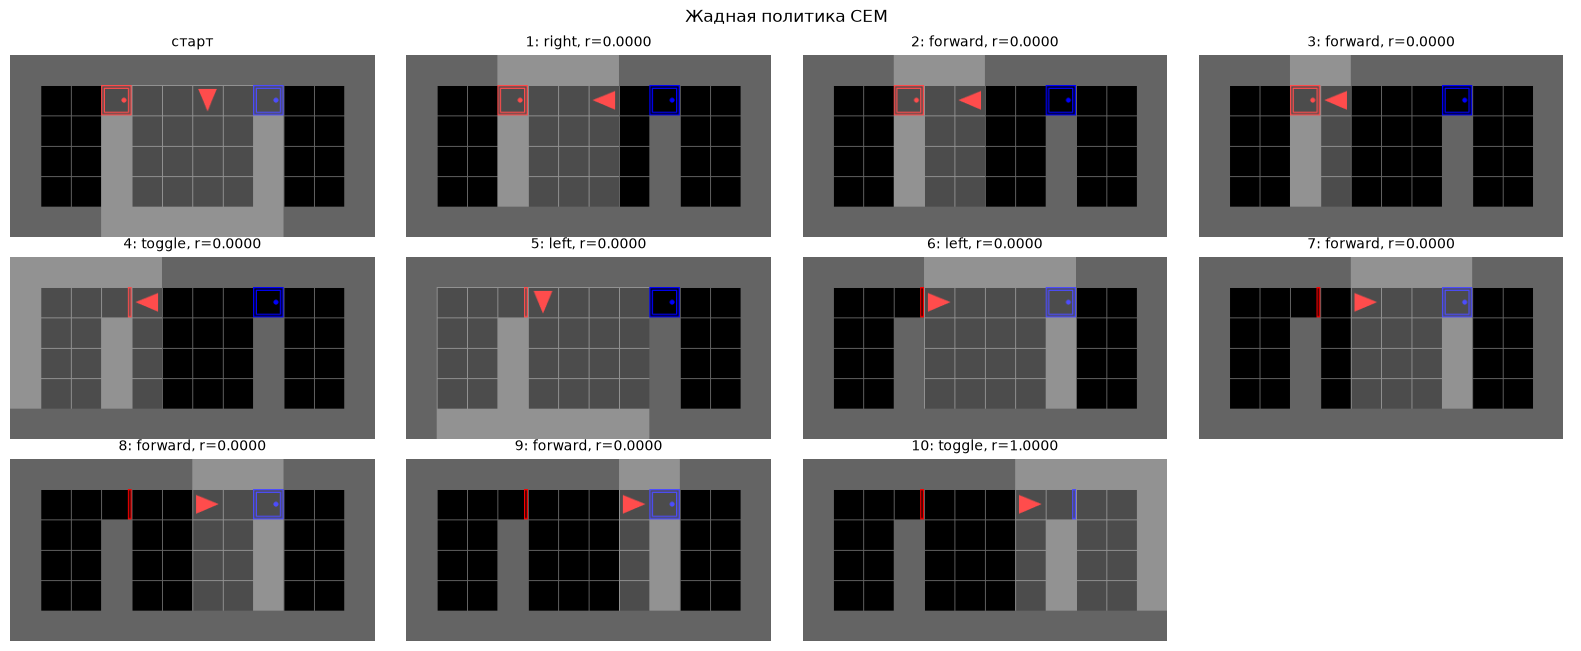

In [34]:
env = make_env()
obs, _ = env.reset(seed=SEED)
cem_actions = []
print(f"{'шаг':>3} | {'состояние':24s} | {'действие CEM':12s} | {'π(a|s)':>6s} | оптимальные по Q* (п. 3)")
for t in range(50):  # предохранитель
    k = state_key(obs, env)
    probs = cem_policy[state_index[k]]
    a = USEFUL_ACTIONS[int(np.argmax(probs))]
    q = get_q_values(envs, V_star, k, GAMMA)
    optimal = [b for b, v in q.items() if np.isclose(v, max(q.values()))]
    (x, y), arrow, red_open = describe(env)
    print(f"{t + 1:3d} | ({x}, {y}) {arrow} красная {'откр.' if red_open else 'закр.':6s} | {ACTION_NAMES[a]:12s} | {probs.max():6.3f} | "
          f"{', '.join(ACTION_NAMES[b] for b in optimal)}")
    assert a in optimal
    cem_actions.append(a)
    obs, r, terminated, truncated, _ = env.step(a)
    if terminated or truncated:
        break

total = run_actions(env, cem_actions, title="Жадная политика CEM")
assert total == 1 and len(cem_actions) == 10

Политика CEM прошла карту за 10 шагов, и на каждом шаге её действие оптимально по $Q^*$ из п. 3. Вероятности выбранных действий близки к 1: политика стала почти детерминированной.

**Что CEM знает о других состояниях.** Посчитаем, в скольких из 196 состояний политика уверена (вероятность лучшего действия больше 0.9).

In [35]:
confident = cem_policy.max(axis=1) > 0.9
on_path = set()
obs, _ = env.reset(seed=SEED)
for a in cem_actions:
    on_path.add(state_index[state_key(obs, env)])
    obs, *_ = env.step(a)

keys = list(state_index)


def show(i):
    (x, y), arrow, red_open = describe(envs[keys[i]])
    probs = cem_policy[i]
    return (f"({x}, {y}) {arrow} красная {'откр.' if red_open else 'закр.'}: "
            + ", ".join(f"{ACTION_NAMES[a]} {p:.2f}" for a, p in zip(USEFUL_ACTIONS, probs)))


print(f"Уверенных состояний: {confident.sum()} из {n_states}")
print(f"Из них на жадном пути: {len(on_path & set(np.flatnonzero(confident)))} из {len(on_path)} состояний пути")
print("\nНа пути, но не уверенных:")
for i in sorted(on_path):
    if not confident[i]:
        print("  ", show(i))
print("Уверенных вне пути:")
for i in np.flatnonzero(confident):
    if i not in on_path:
        print("  ", show(i))
print(f"\nПочти равномерных (max π < 0.3): {(cem_policy.max(axis=1) < 0.3).sum()} из {n_states}")

Уверенных состояний: 10 из 196
Из них на жадном пути: 9 из 10 состояний пути

На пути, но не уверенных:
   (4, 1) ← красная откр.: left 0.63, right 0.37, forward 0.00, toggle 0.00
Уверенных вне пути:
   (4, 1) ↑ красная откр.: left 0.00, right 1.00, forward 0.00, toggle 0.00

Почти равномерных (max π < 0.3): 185 из 196


**Вывод.** CEM уверен только в состояниях на своём пути, и это хорошо видно по исключениям:

- **На пути, но не уверен** — состояние (4, 1, ←) сразу после открытия красной двери. Развернуться можно и через `left`, и через `right`, оба пути по 10 шагов ($Q^*$ равны, см. таблицу выше). Поэтому вероятности делятся между двумя действиями, и это правильно.
- **Уверен вне пути** — (4, 1, ↑): это состояние на втором оптимальном пути, через поворот `right`. Агент проходит его в тех эпизодах, где выбрал `right`, и такие эпизоды тоже попадают в элиту.

Во всех остальных состояниях политика почти равномерная. Если агента поставить в такое состояние, он будет блуждать случайно.

Причина: CEM учится только на сыгранных эпизодах. Состояние, которое не попадает в элиту, получает равномерное распределение (4.5), и сглаживание постепенно стирает то, что о нём было известно. Value iteration из п. 3 перебирает все состояния через модель, поэтому знает оптимальное действие во всех 196.

### Итоги пункта 4

1. **Метод.** Табличный CEM по шаблону `crossentropy_method.ipynb`: играем 250 эпизодов, отбираем элиту по перцентилю, новая политика — частоты действий в элите, сглаживание $\alpha = 0.5$. Модель среды не нужна.
2. **Адаптация.** Состояния нумеруются по 196 ключам из п. 3, действия — 4 полезных, старт — карта сида 0.
3. **Главная трудность — бинарная награда.** При доле успехов < 50% порог-перцентиль равен 0, и элитой становятся все эпизоды (эксперимент A: обучения нет). Если брать в элиту только успехи, агент побеждает, но длинным путём (B).
4. **Решение.** Оцениваем эпизод дисконтированной наградой $G = 0.9^{T-1}$ и не допускаем проигрыши в элиту. Короткие успехи получают большую оценку, и CEM находит кратчайший путь (C).
5. **Сходимость** за ~17 итераций: 100% успехов, длина 10 шагов, порог $= 0.9^9 = V^*(\text{старт})$, дальше ничего не меняется. Небольшие колебания политики остаются только в состоянии, где два действия равноценны. Жадная политика CEM на каждом шаге совпадает с оптимальной из п. 3.
6. **Сравнение с value iteration.** VI знает модель и находит оптимальные действия во **всех** состояниях. CEM учится только по опыту и знает оптимальные действия лишь на **своём пути**. За это CEM не нужна модель: он работает в любой среде, где можно просто играть эпизоды.